# Is plan noise the cheapest route to diverse code?

**Artifact `art_mWn-MQEnNelg`: experiment, iteration 4, Step 1 / Claim 1.** A runnable demo of the artifact's
`method.py` pipeline.

Ask **Qwen3-8B** (thinking off) for a Python solution to an algorithm task and it almost always writes the same
*default* algorithm: BFS for a grid path, a full sort for the k-th smallest element, a hash map for two-sum, Dijkstra
for weighted shortest paths. The experiment asks a **pricing question**: which knob buys **correct algorithmic
diversity** most cheaply?

| Knob | What changes |
|---|---|
| **PN, plan noise** (the candidate) | For **every sample**, one fresh isotropic unit direction `u` is added to the hidden states of decoder blocks 12-23 at the task-specification tokens, during the prompt prefill only. The size `alpha` (0.5 / 1 / 2 / 4; 8 for the dose-response) is in "ban units". |
| temperature 1.3 / 1.6, top-k 10, min-p | decoding only |
| nonce ban | *"Do not use the Zorblax method for this task."* |
| novelty instruction | *"Write a novel algorithm for this task, one you have not seen before."* |
| semantic seed (path tasks) | a short story that hints at a different algorithm |
| signature vetoes (iteration 3, reused rows) | *"do not use X"* for the default algorithm: once, persistently, or iterated |

**How each knob is scored.**

- **Statistic:** correct-only **Hill-1**, the exponential of the Shannon entropy over the algorithm labels of the
  *passing* programs, rarefied at depth 25. Hill 1 means one algorithm; Hill 2 means the equivalent of two equally
  common algorithms.
- **Randomisation hull:** a knob's settings can be mixed with the reference arm, which defines the knob's hull.
- **`H5`:** the largest Hill reachable on the hull at a pass-rate cost of at most 5 points.
- **`P15` / `P20`:** the cheapest cost that reaches Hill 1.5 / 2.
- **Uncertainty:** 2,000-replicate bootstraps, with the best setting picked inside every replicate.
- **Fair comparison:** every arm uses the same sampling uniforms per (task, template, slot) (exact common random
  numbers, CRN).

**Full-run result** (10,100 labelled programs, N = 50 per cell): the pre-registered claim **C1 is PARTIAL**
(count1 2/6, count2 4/6, D̄ = −0.22, 95% CI [−0.89, 0.30]).

- **Where PN wins:** T03 (k-th smallest: H5 2.72 vs 1.96 for the novelty instruction) and T10 (connected components:
  2.09 vs 1.96).
- **Where PN loses:** T06 (1.00 vs 2.73 for the iterated veto) and T2 (1.35 vs 1.93 for the semantic seed).
- **Temperature, top-k 10 and the nonce ban buy no correct algorithmic diversity** (H5 ≤ 1.09). Temperature rewrites
  the code but almost never changes the algorithm.

### What this notebook runs

`method.py` is a stage orchestrator:

```
prompts -> inputs -> screen -> gpu -> label -> commit -> audit -> analyze -> validity -> report
```

Three of these stages need resources a 10-minute CPU notebook does not have:

- `gpu`: Qwen3-8B in FP8 on a 16 GB FP8-capable GPU, 2.5 GPU-hours;
- `label`: runs every program against the frozen bench suites;
- `audit` / `validity`: LLM judges over OpenRouter.

So the notebook does two things:

1. **It shows how the PN knob is built** (direction seeds, CRN uniforms, the displacement-targeted edit), with the
   original functions, on CPU.
2. **It re-runs the `analyze` and `report` stages with the original analysis code** on the labelled programs of the
   six decisive tasks (E6), loaded from `mini_demo_data.json`: 99 (task, arm) cells, 5,020 programs.

The point estimates (knob rows, H5 / P15 / P20) are deterministic, so they reproduce the full run exactly. The
bootstrap intervals use fewer replicates than the original; the config cell lists the original values.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, torch — pre-installed on Colab, install locally only (at Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')
    _pip('torch==2.9.0', '--index-url', 'https://download.pytorch.org/whl/cpu')

In [2]:
from __future__ import annotations

# ---- the import blocks of the original modules (src/cfg.py, src/analysis/*.py, src/hooks.py, src/sampling_v4.py,
#      src/figures.py), merged; argparse / os / resource (CLI and RAM caps of the scripts) are not needed here ----
import ast
import builtins
import hashlib
import itertools
import json
import math
import sys
import time
import zlib
from collections import Counter, defaultdict
from concurrent.futures import ProcessPoolExecutor
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Callable, Iterable, Sequence

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torch
from loguru import logger

# ---- added for the notebook: rendering the result tables ----
import warnings
from IPython.display import Markdown, display

# the bootstrap workers are forked from the (multi-threaded) Jupyter kernel; Python 3.12 warns about that once per fork
warnings.filterwarnings("ignore", message=r".*use of fork\(\) may lead to deadlocks.*", category=DeprecationWarning)
# hull.slsqp_check (the SLSQP diagnostic) calls float() on a 1-element array; harmless NumPy >= 1.25 deprecation notice
warnings.filterwarnings("ignore", message=r"Conversion of an array with ndim > 0 to a scalar", category=DeprecationWarning)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-4/experiment-19/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
meta = data["metadata"]
print(meta["title"])
print(meta["model"])
print(f'{meta["n_cells"]} (task, arm) cells, {meta["n_programs"]} labelled programs')
print(meta["description"])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Is plan noise the cheapest route to diverse code? (art_mWn-MQEnNelg, iteration 4, Step 1 / Claim 1)
Qwen/Qwen3-8B@b968826d9c46dd6066d109eabc6255188de91218 (FP8 W8A8 dynamic, thinking off)
99 (task, arm) cells, 5020 labelled programs
Curated subset of the labelled programs: every (task, arm) cell of the six decisive tasks (E6) that the pre-registered C1 rule reads (this run's TWIN, PN alpha 0.5/1/2/4, T1.3, T1.6, TOPK10, NONCE, NOVELTY, SEMSEED on the path tasks, and the reused iteration-3 veto rows with their own twin), plus PN alpha 8 for the dose-response. One example = one cell with its N labelled programs (template W1-W5 x CRN slot 0-9). Left out: MINP / VS / PLAIN / PNPLAIN arms, the held-out task R2 and the 8 non-movable bench tasks.


## Configuration

Every tunable parameter of the analysis is set here.

- **Already at the full run's values:** the four cheap parameters.
- **Scaled down:** the two bootstrap replicate counts. The full run's values are commented out at the bottom of the
  cell; restoring them adds about 18 minutes on 2 CPUs.
- **What the replicate counts affect:** only the bootstrap intervals (and the verdict's CI criterion). The point
  estimates (knob rows, H5, P15, P20) do not depend on any of these parameters.

With these values the whole notebook finishes in about 2-3 minutes on a 2-CPU machine.

In [5]:
# ---- tunable parameters (demo values) ----
N_BOOT = 200           # primary bootstrap replicates per task (H5/P15/P20; best setting chosen inside each)
N_BOOT_SENS = 50       # replicates of each sensitivity bootstrap (s1, s3, s4, s5, s6, s8)
KNOB_CI_N_BOOT = 2000  # multinomial resamples behind each knob row's 90% Hill interval   (= original)
C1_TASK_BOOT = 2000    # task-bootstrap replicates of D_bar inside the C1 rule              (= original)
PHRASING_N_SUB = 200   # random 20-program subsets per cell in ideas-vs-phrasings           (= original)
FORECAST_NULL_B = 2000 # template-resampling null draws in the forecast score              (= original)
WORKERS = 2            # bootstrap worker processes (forked; Colab has 2 CPUs)

# ---- the full run's values: about 0.17 s per primary and 0.76 s per sensitivity replicate on 2 CPUs,
#      i.e. roughly 18 more minutes than the demo values ----
# N_BOOT = 2000
# N_BOOT_SENS = 1000
# WORKERS = 6

## 1. Design constants (`src/cfg.py`)

These are the shared constants of the design, copied verbatim:

- the six decisive tasks (E6) and each task's **default algorithm**;
- the five ban/neutral templates W1-W5 and the nonce, novelty and verbalized-sampling segments;
- every **arm**: its prompt kind, its decoding settings (T, top-k, min-p), its PN `alpha`, and its knob class;
- the seeds, and the I/O helpers used to write the result files.

**Neutral twin.** The reference arm `TWIN` uses the *neutral twin* prompt. It has the same prohibition frame as a
ban, but a harmless noun is substituted for the banned algorithm, e.g. *"Do not use man, the house and the baby for
this task."* All PN, temperature and top-k arms reuse this prompt.

In [6]:
# ---- from src/cfg.py (verbatim subset; N_BOOT is set in the config cell) ----
# ------------------------------------------------------------------------------------------------ model
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
N_LAYERS = 36
D_MODEL = 4096
MAX_NEW_TOKENS = 1024          # bench tasks and the engine check (the exp17 screen's cap)
TEMPLATE_TAIL = "<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"
# ------------------------------------------------------------------------------------------------ tasks
PATH_TASKS = ("T1", "T2")
E6_TASKS = ("T03", "T05", "T06", "T10", "T1", "T2")            # frozen decisive event set
HELDOUT = ("R2",)
DEFAULT = {"T1": "bfs", "T2": "dijkstra", "T03": "full_sort", "T04": "naive", "T06": "hash_set", "T05": "hash_map",
           "T10": "union_find", "R1": "greedy_end", "T08": "iteration", "R3": "kahn", "T13": "sort_sweep",
           "R6": "binary_search", "T14": "sort_by_count", "T11": "quadratic_dp", "R2": "dfs_parent"}
TEMPLATES: dict[str, tuple[str, str]] = {  # (ban, neutral) -- protocol v2 W1-W5, verbatim
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)
PAD_FILLER = " ."
NONCE_X = "the Zorblax method"
NOVELTY = "Write a novel algorithm for this task, one you have not seen before."
VS_SEGMENT = ("Before writing code, list five different algorithms that solve this task, each with the probability "
              "that you would choose it; then pick one of them at random according to those probabilities and "
              "implement only that one.")
# ------------------------------------------------------------------------------------------------ design
V_BLOCKS = list(range(12, 24))          # PN is added at the task-spec positions of blocks 12-23, prefill only
NORM_BLOCKS = list(range(12, N_LAYERS))  # realised displacement logged at blocks 12-35
SLOTS = list(range(10))                 # k 0-9 per template -> N = 50
PN_ALPHAS = (0.5, 1.0, 2.0, 4.0)
PN_EXTRA_ALPHA = 8.0
# arm -> decoding / prompt definition. prompt kinds: twin, plain, nonce, novelty, semseed, vs
ARMS: dict[str, dict[str, Any]] = {
    "TWIN": {"prompt": "twin", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": None, "knob": "REF"},
    "PN_a0.5": {"prompt": "twin", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": 0.5, "knob": "PN"},
    "PN_a1": {"prompt": "twin", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": 1.0, "knob": "PN"},
    "PN_a2": {"prompt": "twin", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": 2.0, "knob": "PN"},
    "PN_a4": {"prompt": "twin", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": 4.0, "knob": "PN"},
    "PN_a8": {"prompt": "twin", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": 8.0, "knob": "PN_EXTRA"},
    "T1.3": {"prompt": "twin", "T": 1.3, "top_k": 0, "min_p": 0.0, "alpha": None, "knob": "TEMP"},
    "T1.6": {"prompt": "twin", "T": 1.6, "top_k": 0, "min_p": 0.0, "alpha": None, "knob": "TEMP"},
    "TOPK10": {"prompt": "twin", "T": 1.0, "top_k": 10, "min_p": 0.0, "alpha": None, "knob": "TOPK10"},
    "MINP_T1.6": {"prompt": "twin", "T": 1.6, "top_k": 0, "min_p": 0.1, "alpha": None, "knob": "MINP"},
    "MINP_T2.0": {"prompt": "twin", "T": 2.0, "top_k": 0, "min_p": 0.1, "alpha": None, "knob": "MINP"},
    "PLAIN": {"prompt": "plain", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": None, "knob": "REF_PLAIN"},
    "PNPLAIN_a1": {"prompt": "plain", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": 1.0, "knob": "PNPLAIN"},
    "NONCE": {"prompt": "nonce", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": None, "knob": "NONCE"},
    "NOVELTY": {"prompt": "novelty", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": None, "knob": "NOVELTY"},
    "SEMSEED": {"prompt": "semseed", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": None, "knob": "SEMSEED"},
    "VS": {"prompt": "vs", "T": 1.0, "top_k": 0, "min_p": 0.0, "alpha": None, "knob": "VS"},
}
PN_ARMS = ("PN_a0.5", "PN_a1", "PN_a2", "PN_a4")
BOOT_SEED = 20261021
DEPTH = 25

# notebook: results, figures and logs are written next to the notebook (the original wrote into the artifact folder)
RESULTS_DIR = Path("results")
FIG_DIR = Path("figures")
LOG_DIR = Path("logs")
for _d in (RESULTS_DIR, FIG_DIR, LOG_DIR):
    _d.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr) -- exp8/exp17 convention."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed line in {p.name}")
    return out


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with open(tmp, "w") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
    tmp.replace(p)


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())

### The labelled programs

The original analysis read `data/samples.jsonl` (raw generations merged with their labels by `merge_samples()`) and
`data/reused_rows.jsonl` (the iteration-3 veto rows with their own twin). Here both come from the loaded mini data:
one example per (task, arm) cell, expanded back into one row per program.

Each row records:

- the template (W1-W5) and the CRN slot (0-9);
- the mechanism **label** that the frozen runtime/AST labeller gave the program (`bfs`, `dfs`, `quickselect`, ...,
  `other` or `invalid`);
- whether the program **passed** the task's test suite;
- its code and code hash;
- for PN rows, the direction seed and the realised displacement.

In [7]:
# notebook: replaces merge_samples() / read_jsonl(data/reused_rows.jsonl) of src/analysis/run_all.py
cells = data["datasets"][0]["examples"]
samples = [dict(s, task=c["task"], arm=c["arm"], knob_class=c["knob_class"], engine=c["engine"],
                sample_id=f'{c["task"]}|{c["arm"]}|{s["template"]}|{s["slot"]}')
           for c in cells if c["source"] == "this_run" for s in c["samples"]]
reused = [dict(s, task=c["task"], arm=c["arm"], engine=c["engine"], sample_id=f'reused|{c["task"]}|{c["arm"]}|{s["slot"]}')
          for c in cells if c["source"] == "reused_iter3" for s in c["samples"]]
print(f"{len(samples)} programs of this run (Qwen3-8B FP8) + {len(reused)} reused iteration-3 veto rows (vLLM bf16)")
print()
print(f"{'task':<5} {'default':<11} {'arms':>4}  label counts over every arm of the task")
for t in E6_TASKS:
    rs = [r for r in samples + reused if r["task"] == t]
    print(f"{t:<5} {DEFAULT[t]:<11} {len({r['arm'] for r in rs}):>4}  {dict(Counter(r['label'] for r in rs).most_common(6))}")

3400 programs of this run (Qwen3-8B FP8) + 1620 reused iteration-3 veto rows (vLLM bf16)

task  default     arms  label counts over every arm of the task
T03   full_sort     17  {'full_sort': 583, 'quickselect': 197, 'invalid': 33, 'other': 19, 'size_k_heap': 16, 'heapify_pop': 2}
T05   hash_map      17  {'hash_map': 781, 'invalid': 46, 'brute_force': 17, 'other': 4, 'sort_two_pointers': 2}
T06   hash_set      15  {'hash_set': 627, 'invalid': 50, 'sort_adjacent': 32, 'other': 27, 'floyd': 10, 'index_marking': 4}
T10   union_find    15  {'union_find': 493, 'invalid': 122, 'dfs': 117, 'other': 13, 'bfs': 5}
T1    bfs           17  {'bfs': 801, 'dfs': 54, 'other': 39, 'invalid': 3, 'dijkstra': 2, 'bibfs': 1}
T2    dijkstra      18  {'dijkstra': 771, 'other': 77, 'bf_spfa': 69, 'invalid': 2, 'floyd': 1}


### What the knobs look like

The first sentence of the prompt (the *segment*) is the only part of the prompt that differs between prompt kinds.
The PN, temperature and top-k arms all use the neutral-twin prompt; only their decoding settings or their activation
edit differ.

In [8]:
# prompts of the grid-path task T1: the full twin prompt once, then the segment of every other prompt kind
# (twin / nonce / semantic seed come in templates W1-W5; novelty is a single prompt whose 50 rows differ by CRN key)
shown = set()
for c in cells:
    if c["task"] == "T1" and c["source"] == "this_run" and c["prompt_kind"] not in shown:
        shown.add(c["prompt_kind"])
        text = c["prompt_example"] if c["prompt_kind"] == "twin" else c["prompt_example"].split("\n\n")[0]
        print(f"----- prompt kind '{c['prompt_kind']}', template {c['prompt_example_template']} "
              f"(first arm using it: {c['arm']}) -----\n{text}\n")

print(f"{'arm':<11} {'knob class':<10} {'prompt':<8} {'T':>4} {'top_k':>6} {'min_p':>6} {'alpha':>6}")
for arm, a in ARMS.items():
    print(f"{arm:<11} {a['knob']:<10} {a['prompt']:<8} {a['T']:>4} {a['top_k']:>6} {a['min_p']:>6} {str(a['alpha']):>6}")

----- prompt kind 'twin', template W1 (first arm using it: TWIN) -----
Do not use man, the house and the baby for this task.

Task: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. grid is a list of equal-length strings with between 1 and 30 rows and between 1 and 30 columns; the character . is a free cell and the character # is a wall. start and goal are (row, col) tuples of 0-based indices. A move goes to one of the 4 orthogonal neighbours (up, down, left, right) and may not leave the grid or enter a wall. Return a list of (row, col) tuples that begins with start, ends with goal, and in which consecutive cells are neighbours and every cell is free. Any valid path is accepted; it does not have to be the shortest. If start equals goal and the cell is free, return [start]. If no path exists, or start or goal is a wall, return [].

Use only the Python standard library. Return only one ```python code block containing the function solve and an

## 2. The `gpu` stage: how plan noise is applied (shown on CPU)

The generation stage (`src/gpu_stage.py`, `src/sampling_v4.py`, `src/engine_v4.py`) cannot run here: it loads
Qwen3-8B, quantises it to FP8 W8A8, and decodes 10,100 programs. Its three key ingredients are small, though, and run
on CPU with the original functions.

1. **Exact CRN.** Slot `k` of template `w` of a task draws its token at every step by inverse-CDF sampling from the
   uniform stream `u_stream(task, w, k)`. The key leaves out the arm, so *every arm* decodes slot `k` with the same
   uniforms. Any difference between two arms at the same slot is caused by the knob, not by sampling luck.
2. **One fresh direction per sample.** A PN row draws `x ~ N(0, I_4096)` from the seed
   `stable_seed(task, arm, w, k)` and normalises it. Every program therefore gets its own isotropic direction `u`,
   shared across blocks 12-23 and all spec positions.
3. **Displacement-targeted edit** (`make_edits('RAND', ...)` in `src/hooks.py`). At each hooked block `l` and spec
   position `p`, the hidden state is moved so that its displacement from the *clean twin* along `u` is **exactly**
   `alpha * n[l, p]`, where `n[l, p]` is the "ban unit" (the size of a real ban's displacement there). Because each
   block re-targets the displacement, edits do not compound along `u`; the orthogonal components are left alone.

In [9]:
# ---- from src/engine_v4.py and src/sampling_v4.py (verbatim) ----
# ------------------------------------------------------------------------------------------------ sampling
def u_stream(*key: Any, n: int = MAX_NEW_TOKENS) -> np.ndarray:
    return np.random.Generator(np.random.PCG64(stable_seed(*key))).random(n)


def pn_direction(task: str, arm: str, w: str, k: int) -> tuple[int, np.ndarray]:
    seed = stable_seed(task, arm, w, k)
    x = np.random.Generator(np.random.PCG64(seed)).standard_normal(D_MODEL)
    return seed, (x / np.linalg.norm(x)).astype(np.float32)


# (1) every PN row's logged direction seed is stable_seed(task, arm, template, slot): one fresh direction per sample
pn_rows = [r for r in samples if r["arm"].startswith("PN_")]
n_match = sum(pn_direction(r["task"], r["arm"], r["template"], r["slot"])[0] == r["direction_seed"] for r in pn_rows)
print(f"direction seeds re-derived: {n_match}/{len(pn_rows)} PN rows match the seed logged during generation")

# (2) fresh isotropic directions in 4096-d are nearly orthogonal: |cos| is about 1/sqrt(4096) = 0.016
U_dirs = np.stack([pn_direction("T03", "PN_a1", "W1", k)[1] for k in SLOTS])
cosm = U_dirs @ U_dirs.T
print(f"10 directions (T03, PN_a1, W1, slots 0-9): mean |cos| between different samples = "
      f"{np.abs(cosm[~np.eye(10, dtype=bool)]).mean():.4f}")

# (3) CRN: every row's logged uniform-stream seed is stable_seed(task, template, slot); the arm is not part of the key,
#     so all arms decode slot k with the same uniforms
n_crn = sum(r["u_seed"] == stable_seed(r["task"], r["template"], r["slot"]) for r in samples)
print(f"CRN keys re-derived: {n_crn}/{len(samples)} rows of {len({r['arm'] for r in samples})} arms use u_stream(task, template, slot)")
print("first 5 CRN uniforms of slot (T1, W1, 0):", np.round(u_stream("T1", "W1", 0)[:5], 4),
      f"-- shared by all {sum(1 for c in cells if c['task'] == 'T1' and c['source'] == 'this_run')} arms of T1 in this run")

direction seeds re-derived: 1500/1500 PN rows match the seed logged during generation
10 directions (T03, PN_a1, W1, slots 0-9): mean |cos| between different samples = 0.0121
CRN keys re-derived: 3400/3400 rows of 12 arms use u_stream(task, template, slot)
first 5 CRN uniforms of slot (T1, W1, 0): [0.1015 0.0066 0.2867 0.6767 0.5946] -- shared by all 12 arms of T1 in this run


The original hook, run on random tensors (no model). Whatever displacement along `u` the incoming state already
carries (here 2.5 units, as if earlier hooked blocks had pushed it), the edit sets it to exactly `alpha * n[l, p]` and
leaves every orthogonal component untouched.

In [10]:
# ---- from src/hooks.py (verbatim): the block-output edits; PN uses kind 'RAND' ----
def make_edits(kind: str, a: int, b: int, u: dict[int, torch.Tensor] | None, n: dict[int, torch.Tensor] | None,
               h_ref: dict[int, torch.Tensor] | None, alpha: float = 0.0, r: torch.Tensor | None = None,
               log: dict[int, list[float]] | None = None) -> dict[int, Callable[[torch.Tensor], torch.Tensor]]:
    """Edits for positions [a, b) at V_BLOCKS. u/vhat: {l: [D] fp32 unit}; n: {l: [b-a] fp32}; h_ref: {l: [b-a, D]}."""
    edits = {}
    for l in V_BLOCKS:
        def f(h: torch.Tensor, l: int = l) -> torch.Tensor:
            hs = h[:, a:b].float()
            if kind in ("ADD", "RAND"):
                ul = u[l]
                comp = (hs - h_ref[l]) @ ul                       # [1, |S|]
                coef = alpha * n[l] - comp
                new = hs + coef[..., None] * ul
                edit = coef.abs()
            elif kind == "SUB_plain":
                vl = u[l]
                proj = hs @ vl
                new = hs - proj[..., None] * vl
                edit = proj.abs()
            elif kind == "SUB_affine":
                vl = u[l]
                proj = (hs - h_ref[l]) @ vl
                new = hs - proj[..., None] * vl
                edit = proj.abs()
            elif kind == "SUB_rand":
                vl = u[l]
                proj = (hs @ vl).abs()
                new = hs - proj[..., None] * r
                edit = proj
            else:
                raise ValueError(kind)
            if log is not None:
                log.setdefault(l, []).append(float(edit.mean()))
            h = h.clone()
            h[:, a:b] = new.to(h.dtype)
            return h
        edits[l] = f
    return edits


# toy check (random tensors, width 64 instead of 4096): one prompt of 12 tokens with spec positions [3, 9)
torch.manual_seed(0)
D_toy, P_toy, a_toy, b_toy, alpha_toy = 64, 12, 3, 9, 2.0
x_toy = torch.randn(D_toy)
u_toy = x_toy / x_toy.norm()                                        # the sample's unit direction
h_clean = torch.randn(1, P_toy, D_toy)                              # clean neutral-twin block output
n_toy = {l: torch.rand(b_toy - a_toy) + 0.5 for l in V_BLOCKS}      # ban units n[l, p]
edits = make_edits("RAND", a_toy, b_toy, {l: u_toy for l in V_BLOCKS}, n_toy,
                   {l: h_clean[0, a_toy:b_toy] for l in V_BLOCKS}, alpha=alpha_toy)
h_in = h_clean + 0.3 * torch.randn(1, P_toy, D_toy) + 2.5 * u_toy   # drifted state entering block 12's hook
h_out = edits[12](h_in)
disp_u = (h_out[0, a_toy:b_toy] - h_clean[0, a_toy:b_toy]) @ u_toy
print("displacement along u after the edit:", disp_u.numpy().round(4))
print("target alpha * n[12, p]            :", (alpha_toy * n_toy[12]).numpy().round(4))
orth = lambda h: h - (h @ u_toy)[..., None] * u_toy
print("orthogonal components unchanged:", torch.allclose(orth(h_out), orth(h_in), atol=1e-5),
      "| tokens outside the spec unchanged:", torch.equal(h_out[:, :a_toy], h_in[:, :a_toy]))

displacement along u after the edit: [2.1003 1.628  1.1625 2.4047 2.128  1.5995]
target alpha * n[12, p]            : [2.1003 1.628  1.1625 2.4047 2.128  1.5995]
orthogonal components unchanged: True | tokens outside the spec unchanged: True


**The real run.** During generation the realised displacement of every PN prefill was logged. The table below gives,
per arm, the largest relative error along `u` over blocks 12-23, and the mean displacement norm at the spec positions
at blocks 12, 23 and 35.

- **Accuracy:** the relative error stays below 0.002 on every row.
- **Dose:** the displacement at block 12 grows linearly with `alpha`.
- **Propagation:** downstream blocks carry a much larger total displacement, because the edit propagates through
  the network.

In [11]:
by_alpha = defaultdict(list)
for r in pn_rows:
    by_alpha[r["arm"]].append(r["realised_disp"])
print(f"{'arm':<8} {'rows':>5} {'max rel. error along u':>23} {'|disp| at S, block 12':>22} {'block 23':>9} {'block 35':>9}")
for arm in ("PN_a0.5", "PN_a1", "PN_a2", "PN_a4", "PN_a8"):
    d = by_alpha[arm]
    print(f"{arm:<8} {len(d):>5} {max(x['relerr_u_max'] for x in d):>23.5f} {np.mean([x['S_b12'] for x in d]):>22.2f} "
          f"{np.mean([x['S_b23'] for x in d]):>9.1f} {np.mean([x['S_b35'] for x in d]):>9.1f}")

arm       rows  max rel. error along u  |disp| at S, block 12  block 23  block 35
PN_a0.5    300                 0.00152                   3.26      29.8     148.3
PN_a1      300                 0.00096                   6.52      55.7     271.1
PN_a2      300                 0.00048                  13.04     105.5     505.6
PN_a4      300                 0.00020                  26.07     192.5     818.4
PN_a8      300                 0.00014                  52.14     322.4    1114.0


## 3. The `analyze` stage: correct-only Hill and the randomisation hull

`method.py analyze` runs `python -m analysis.run_all` and then `python -m analysis.descriptive`. Their building blocks
come first.

**Step-0 statistic** (`src/analysis/stats_step0.py`, a byte-identical copy of the iteration-3 evaluation's
`stats.py`): rarefied Hill-1 is the mean of `exp(Shannon)` over subsamples of 25 correct programs drawn without
replacement. Only the three functions this analysis calls are shown. The file also holds Wilson and Newcombe
intervals, Cohen's kappa, Kish's effective sample size and PSIS k-hat, which the C1 analysis never calls.

In [12]:
# ---- from src/analysis/stats_step0.py (verbatim; the functions the analysis calls) ----
def _hill_rows(M: np.ndarray) -> np.ndarray:
    n = M.sum(axis=1, keepdims=True)
    p = np.where(M > 0, M / np.maximum(n, 1), 1.0)
    return np.exp(-(np.where(M > 0, (M / np.maximum(n, 1)) * np.log(p), 0.0)).sum(axis=1))


def rarefied_hill1(counts: Sequence[float], depth: int, n_sub: int = 1000,
                   rng: np.random.Generator | None = None) -> float:
    """Mean over n_sub subsamples of size `depth` drawn WITHOUT replacement of exp(Shannon) of the subsample."""
    c = np.asarray(counts, dtype=np.int64)
    c = c[c > 0]
    if c.sum() < depth or depth <= 0:
        return math.nan
    if len(c) == 1:
        return 1.0
    rng = rng or np.random.default_rng(0)
    M = rng.multivariate_hypergeometric(c, depth, size=n_sub)
    return float(_hill_rows(M.astype(float)).mean())


def boot_rarefied_hill1(counts: Sequence[float], depth: int, n_boot: int = 2000, n_sub: int = 200,
                        rng: np.random.Generator | None = None, conf: float = 0.90) -> tuple[float, float]:
    """Percentile interval of rarefied Hill-1 over multinomial resamples of the row (programs resampled)."""
    c = np.asarray(counts, dtype=np.int64)
    c = c[c > 0]
    n = int(c.sum())
    if n < depth:
        return (math.nan, math.nan)
    rng = rng or np.random.default_rng(1)
    p = c / n
    vals = np.empty(n_boot)
    for b in range(n_boot):
        cb = rng.multinomial(n, p)
        cb = cb[cb > 0]
        if len(cb) == 1:
            vals[b] = 1.0
            continue
        M = rng.multivariate_hypergeometric(cb, depth, size=n_sub)
        vals[b] = _hill_rows(M.astype(float)).mean()
    a = (1 - conf) / 2
    return (float(np.quantile(vals, a)), float(np.quantile(vals, 1 - a)))

**The randomisation hull** (`src/analysis/hull.py`, complete).

- **Vertices:** a knob class is a set of vertices, the reference arm plus the knob's settings. Each vertex carries
  its correct-idea rates `r_j` and its pass rate.
- **Mixtures:** a mixture `lambda` of the vertices has rates `sum lambda_j r_j` and costs
  `100 * (pass_ref - pass(lambda))` points.
- **Hill on the hull:** population-rarefied Hill-1 at depth 25, computed with **one fixed matrix of uniforms**
  (common random numbers again), so the objective is smooth in `lambda`.
- **Search:** every edge of the simplex on a 0.025 grid, plus the exact cost-5 boundary point of each edge, then a
  golden-section refinement on the best edge.
- **`H5`** is the best Hill at cost ≤ 5. **`P15` / `P20`** are the smallest costs at which Hill reaches 1.5 / 2.

In [13]:
# Randomisation hull of a knob class (plan 6.3), vectorised.
#
# A knob class K has a reference arm 0 and settings S_K. Arm j has r_j = correct counts per idea category / N_j and a
# pass rate pass_j. A mixture lambda on the simplex over {0} u S_K has r(lambda) = sum lambda_j r_j, pass(lambda) =
# sum lambda_j pass_j, composition q = r / sum(r) and cost = 100 (pass_0 - pass(lambda)) in points (negative costs are
# feasible). Hill on the hull = POPULATION-RAREFIED Hill-1 at depth 25: the mean of exp(Shannon) over n_sub
# multinomial(25, q) draws made with ONE fixed uniform matrix U[n_sub, 25] (common random numbers across every
# evaluation, so the objective is smooth in lambda). Search: every pairwise edge of the simplex on a 0.025 lambda grid,
# plus the exact cost = 5 boundary point of each edge, then a golden-section refinement on the best edge.
# H5 = max Hill over hull points with cost <= 5. P_thr = the smallest c >= 0 such that the max Hill at cost <= c
# reaches thr (computed from the same grid, crossings refined by bisection on the edge), else None ('not reached').

GRID = np.round(np.arange(0.0, 1.0 + 1e-9, 0.025), 6)


def fixed_uniforms(n_sub: int, depth: int = 25, seed: int = 20261021) -> np.ndarray:
    return np.random.default_rng(seed).random((n_sub, depth))


def pop_hill_loop(Q: np.ndarray, U: np.ndarray) -> np.ndarray:
    """Reference implementation of pop_hill (row loop); kept for the equivalence unit test."""
    G, C = Q.shape
    if C == 1:
        return np.ones(G)
    cdf = np.cumsum(Q, axis=1)
    cdf[:, -1] = 1.0 + 1e-12
    n_sub, depth = U.shape
    idx = np.empty((G, n_sub, depth), dtype=np.int16)
    flatU = U.ravel()
    for g in range(G):
        idx[g] = np.searchsorted(cdf[g], flatU, side="right").reshape(n_sub, depth)
    np.minimum(idx, C - 1, out=idx)
    H = np.zeros((G, n_sub))
    for c in range(C):
        cnt = (idx == c).sum(axis=2)
        pc = cnt / depth
        with np.errstate(divide="ignore", invalid="ignore"):
            H -= np.where(cnt > 0, pc * np.log(np.where(cnt > 0, pc, 1.0)), 0.0)
    return np.exp(H).mean(axis=1)


def pop_hill(Q: np.ndarray, U: np.ndarray) -> np.ndarray:
    """Q [G, C] compositions (rows sum to 1); U [n_sub, depth] -> [G] mean exp(Shannon) of multinomial(depth, q)
    drawn by inverse CDF from the fixed uniforms (one searchsorted over row-offset CDFs, one bincount)."""
    G, C = Q.shape
    if C == 1 or G == 0:
        return np.ones(G)
    cdf = np.cumsum(Q, axis=1)
    cdf[:, -1] = 1.0 + 1e-12
    n_sub, depth = U.shape
    off = 2.0 * np.arange(G, dtype=float)
    flat_cdf = (cdf + off[:, None]).ravel()
    u = (U.ravel()[None, :] + off[:, None]).ravel()
    pos = np.searchsorted(flat_cdf, u, side="right")
    idx = pos - np.repeat(np.arange(G) * C, n_sub * depth)
    np.minimum(idx, C - 1, out=idx)
    key = np.repeat(np.arange(G * n_sub), depth) * C + idx
    cnt = np.bincount(key, minlength=G * n_sub * C).reshape(G, n_sub, C)
    pc = cnt / depth
    with np.errstate(divide="ignore", invalid="ignore"):
        H = -np.where(cnt > 0, pc * np.log(np.where(cnt > 0, pc, 1.0)), 0.0).sum(axis=2)
    return np.exp(H).mean(axis=1)


class Hull:
    """Vertices: R [m, C] (correct-idea rates), pas [m] (pass rates); vertex 0 is the reference."""

    def __init__(self, R: np.ndarray, pas: np.ndarray, U: np.ndarray, edges: str = "all"):
        self.R = np.asarray(R, float)
        self.pas = np.asarray(pas, float)
        self.U = U
        m = len(self.pas)
        self.m = m
        self.cost_v = 100.0 * (self.pas[0] - self.pas)
        if m == 1:
            self.edges = []
        elif edges == "twin":   # twin-segment-only hull (sensitivity s1)
            self.edges = [(0, j) for j in range(1, m)]
        else:
            self.edges = list(itertools.combinations(range(m), 2))
        self._grid = None

    def eval_lams(self, L: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """L [G, m] mixture weights -> (hill [G], cost [G]); a point with no correct mass has Hill nan."""
        r = L @ self.R
        tot = r.sum(axis=1)
        cost = 100.0 * (self.pas[0] - L @ self.pas)
        hill = np.full(len(L), np.nan)
        ok = tot > 0
        if ok.any():
            Q = r[ok] / tot[ok, None]
            keep = Q.max(axis=0) > 0
            hill[ok] = pop_hill(Q[:, keep] if keep.any() else Q, self.U)
        return hill, cost

    def _edge_points(self, i: int, j: int, lam: np.ndarray) -> np.ndarray:
        L = np.zeros((len(lam), self.m))
        L[:, i] = 1.0 - lam
        L[:, j] += lam
        return L

    def grid(self) -> list[dict[str, Any]]:
        """Evaluate every edge on the 0.025 grid (cached)."""
        if self._grid is not None:
            return self._grid
        out = []
        if not self.edges:
            h, c = self.eval_lams(np.ones((1, 1)))
            out.append({"edge": (0, 0), "lam": np.array([0.0]), "hill": h, "cost": c})
        else:
            Ls = [self._edge_points(i, j, GRID) for i, j in self.edges]
            h, c = self.eval_lams(np.vstack(Ls))
            n = len(GRID)
            for e, (i, j) in enumerate(self.edges):
                out.append({"edge": (i, j), "lam": GRID, "hill": h[e * n:(e + 1) * n], "cost": c[e * n:(e + 1) * n]})
        self._grid = out
        return out

    def best_at_cost(self, c_max: float, refine: bool = True) -> dict[str, Any]:
        """max Hill over hull points with cost <= c_max (grid + exact boundary points + golden refinement)."""
        best = {"hill": -np.inf, "cost": None, "edge": None, "lam": None}
        bnd_L, bnd_meta = [], []
        for g in self.grid():
            feas = g["cost"] <= c_max + 1e-9
            if feas.any():
                hh = np.where(feas & np.isfinite(g["hill"]), g["hill"], -np.inf)
                k = int(np.argmax(hh))
                if hh[k] > best["hill"]:
                    best = {"hill": float(hh[k]), "cost": float(g["cost"][k]), "edge": g["edge"],
                            "lam": float(g["lam"][k])}
            if g["edge"] != (0, 0):
                i, j = g["edge"]
                ci, cj = self.cost_v[i], self.cost_v[j]
                if (ci - c_max) * (cj - c_max) < 0:  # boundary crossing inside the edge
                    lam_b = (c_max - ci) / (cj - ci)
                    bnd_L.append(self._edge_points(i, j, np.array([lam_b]))[0])
                    bnd_meta.append((g["edge"], lam_b))
        if bnd_L:
            hb, cb = self.eval_lams(np.array(bnd_L))
            for (e, lb), h_, c_ in zip(bnd_meta, hb, cb):
                if np.isfinite(h_) and h_ > best["hill"]:
                    best = {"hill": float(h_), "cost": float(c_), "edge": e, "lam": float(lb)}
        if refine and best["edge"] not in (None, (0, 0)):
            best = self._golden(best, c_max)
        if not np.isfinite(best["hill"]):
            best["hill"] = None
        return best

    def _golden(self, best: dict[str, Any], c_max: float, iters: int = 14) -> dict[str, Any]:
        i, j = best["edge"]
        ci, cj = self.cost_v[i], self.cost_v[j]
        lo, hi = max(0.0, best["lam"] - 0.025), min(1.0, best["lam"] + 0.025)
        # restrict to the feasible part of the edge
        if cj != ci:
            lam_b = (c_max - ci) / (cj - ci)
            if cj > ci:
                hi = min(hi, lam_b)
            else:
                lo = max(lo, lam_b)
        elif ci > c_max + 1e-9:
            return best
        if hi <= lo:
            return best
        gr = (math.sqrt(5) - 1) / 2

        def f(x):
            h, c = self.eval_lams(self._edge_points(i, j, np.array([x])))
            return (h[0] if np.isfinite(h[0]) else -np.inf), c[0]

        a, b = lo, hi
        x1, x2 = b - gr * (b - a), a + gr * (b - a)
        f1, f2 = f(x1)[0], f(x2)[0]
        for _ in range(iters):
            if f1 > f2:
                b, x2, f2 = x2, x1, f1
                x1 = b - gr * (b - a)
                f1 = f(x1)[0]
            else:
                a, x1, f1 = x1, x2, f2
                x2 = a + gr * (b - a)
                f2 = f(x2)[0]
        xm = x1 if f1 > f2 else x2
        hm, cm = f(xm)
        if hm > best["hill"] and cm <= c_max + 1e-9:
            return {"hill": float(hm), "cost": float(cm), "edge": (i, j), "lam": float(xm)}
        return best

    def price(self, thr: float, tol: float = 0.1, fast: bool = False) -> float | None:
        """Smallest c >= 0 with max Hill at cost <= c >= thr (None if never reached on the hull). fast=True (inside
        bootstrap replicates): the crossing between grid neighbours is linearly interpolated, not bisected."""
        cands = []
        for g in self.grid():
            h, c, lam = g["hill"], g["cost"], g["lam"]
            ok = np.isfinite(h) & (h >= thr)
            if not ok.any():
                continue
            k = np.where(ok)[0]
            cands.append(float(np.min(c[k])))
            if g["edge"] == (0, 0):
                continue
            # refine crossings between neighbours where hill crosses thr and the crossing point is cheaper
            for a in range(len(lam) - 1):
                if (ok[a] != ok[a + 1]) and np.isfinite(h[a]) and np.isfinite(h[a + 1]):
                    if fast:
                        t_ = (thr - h[a]) / (h[a + 1] - h[a]) if h[a + 1] != h[a] else 0.0
                        cands.append(float(c[a] + t_ * (c[a + 1] - c[a])))
                        continue
                    lo_l, hi_l = (lam[a], lam[a + 1]) if ok[a + 1] else (lam[a + 1], lam[a])
                    i, j = g["edge"]
                    for _ in range(8):  # bisection on lambda: lo_l fails, hi_l passes
                        mid = 0.5 * (lo_l + hi_l)
                        hm, _ = self.eval_lams(self._edge_points(i, j, np.array([mid])))
                        if np.isfinite(hm[0]) and hm[0] >= thr:
                            hi_l = mid
                        else:
                            lo_l = mid
                    _, cc = self.eval_lams(self._edge_points(i, j, np.array([hi_l])))
                    cands.append(float(cc[0]))
        if not cands:
            return None
        return max(0.0, round(min(cands), 1))

    def summary(self, refine: bool = True, with_price: bool = True) -> dict[str, Any]:
        b5 = self.best_at_cost(5.0, refine=refine)
        out = {"H5": b5["hill"], "H5_cost": b5["cost"], "H5_edge": b5["edge"], "H5_lam": b5["lam"]}
        if with_price:
            out["P15"] = self.price(1.5, fast=not refine)
            out["P20"] = self.price(2.0, fast=not refine)
        return out


def slsqp_check(h: Hull, c_max: float = 5.0, n_starts: int = 6, seed: int = 0) -> float | None:
    """Full-simplex multistart SLSQP over 3-vertex faces; returns the best Hill found (point-estimate check)."""
    from scipy.optimize import minimize

    if h.m < 3:
        return None
    rng = np.random.default_rng(seed)
    best = -np.inf
    for tri in itertools.combinations(range(h.m), 3):
        for _ in range(n_starts):
            x0 = rng.dirichlet(np.ones(3))

            def f(x, tri=tri):
                L = np.zeros((1, h.m))
                L[0, list(tri)] = np.clip(x, 0, None) / max(np.clip(x, 0, None).sum(), 1e-12)
                v, _ = h.eval_lams(L)
                return -(v[0] if np.isfinite(v[0]) else 0.0)

            def con(x, tri=tri):
                L = np.zeros((1, h.m))
                L[0, list(tri)] = np.clip(x, 0, None) / max(np.clip(x, 0, None).sum(), 1e-12)
                return c_max - float(100.0 * (h.pas[0] - L @ h.pas))

            r = minimize(f, x0, method="SLSQP", bounds=[(0, 1)] * 3,
                         constraints=[{"type": "eq", "fun": lambda x: x.sum() - 1}, {"type": "ineq", "fun": con}],
                         options={"maxiter": 60})
            if r.success or True:
                x = np.clip(r.x, 0, None)
                if con(x) >= -1e-6:
                    best = max(best, -f(x))
    return float(best) if np.isfinite(best) else None


def dial_interp_h5(points: list[tuple[float, float]], c_max: float = 5.0) -> float | None:
    """Sensitivity s3: piecewise-linear Hill along the dial (points ordered by setting strength, starting at the
    reference): max interpolated Hill at cost <= c_max."""
    best = None
    pts = [(c, h) for c, h in points if h is not None and np.isfinite(h)]
    for (c0, h0), (c1, h1) in zip(pts[:-1], pts[1:]):
        for c, hv in ((c0, h0), (c1, h1)):
            if c <= c_max and (best is None or hv > best):
                best = hv
        if (c0 - c_max) * (c1 - c_max) < 0:
            t = (c_max - c0) / (c1 - c0)
            hv = h0 + t * (h1 - h0)
            if best is None or hv > best:
                best = hv
    if len(pts) == 1 and pts[0][0] <= c_max:
        best = pts[0][1]
    return best


# ------------------------------------------------------------------------------------------------ unit tests
def unit_tests() -> dict[str, Any]:
    U = fixed_uniforms(1000)
    res = {}
    # (a) twin all default, setting all alternative, equal pass -> max at lambda 0.5, Hill = rarefied (0.5, 0.5)
    h = Hull(np.array([[1.0, 0.0], [0.0, 1.0]]), np.array([1.0, 1.0]), U)
    s = h.summary()
    ref = pop_hill(np.array([[0.5, 0.5]]), U)[0]
    res["a_lam"] = s["H5_lam"]
    res["a_pass"] = abs(s["H5_lam"] - 0.5) < 0.03 and abs(s["H5"] - ref) < 0.01 and abs(s["H5_cost"]) < 1e-9
    # (b) the same with a 10-point pass cost -> optimum on the cost = 5 boundary
    h = Hull(np.array([[1.0, 0.0], [0.0, 0.9]]), np.array([1.0, 0.9]), U)
    s = h.summary()
    res["b_cost"] = s["H5_cost"]
    res["b_pass"] = abs(s["H5_cost"] - 5.0) < 0.05
    # (c) a knob identical to the twin -> H5 = the twin's Hill
    R0 = np.array([0.6, 0.3, 0.1])
    h = Hull(np.vstack([R0, R0]), np.array([1.0, 1.0]), U)
    s = h.summary()
    res["c_pass"] = abs(s["H5"] - pop_hill(R0[None] / R0.sum(), U)[0]) < 1e-9
    # (d) adding a setting never decreases H5
    rng = np.random.default_rng(3)
    ok = True
    for _ in range(20):
        R = rng.dirichlet(np.ones(4), size=3) * rng.uniform(0.6, 1.0, size=(3, 1))
        pas = R.sum(1)
        a = Hull(R[:2], pas[:2], U).summary(with_price=False)["H5"]
        b = Hull(R, pas, U).summary(with_price=False)["H5"]
        ok &= (b is not None and a is not None and b >= a - 1e-9)
    res["d_pass"] = bool(ok)
    # edge search vs full-simplex SLSQP on random 5-vertex cases (point-estimate check)
    gaps = []
    U2 = fixed_uniforms(300)
    for t in range(4):
        R = rng.dirichlet(np.ones(4) * 0.5, size=5) * rng.uniform(0.85, 1.0, size=(5, 1))
        hh = Hull(R, R.sum(1), U2)
        e = hh.summary(with_price=False)["H5"]
        q = slsqp_check(hh, n_starts=2, seed=t)
        gaps.append((q - e) if (q is not None and e is not None) else 0.0)
    res["slsqp_minus_edge_max"] = float(max(gaps))
    res["slsqp_pass"] = res["slsqp_minus_edge_max"] <= 0.02
    res["all_pass"] = all(res[k] for k in ("a_pass", "b_pass", "c_pass", "d_pass", "slsqp_pass"))
    return res

The hull's pre-registered unit tests (results/hull_unit_tests.json in the original run):

- **(a)** a 50/50 mixture of two pure arms is the optimum at zero cost;
- **(b)** with a 10-point pass cost, the optimum sits on the cost-5 boundary;
- **(c)** a knob identical to the twin has H5 equal to the twin's Hill;
- **(d)** adding a setting never decreases H5;
- plus a check of the edge search against a full-simplex SLSQP optimiser.

Tests (a)-(d) pass. The SLSQP diagnostic fails here exactly as it did in the original run (gap 0.19, deviation
`D-hull-edges` in the artifact's `results/deviations.jsonl`). On random 5-vertex Dirichlet(0.5) cases, a 3-vertex
mixture can beat every edge. The pre-registered search therefore stays edge-restricted, and a 3-vertex-face grid
check is reported per class on the real data (`triangle_minus_edge`, printed with the point prices in section 3b).

In [14]:
hull_tests = unit_tests()
write_json(RESULTS_DIR / "hull_unit_tests.json", hull_tests)
print(json.dumps(hull_tests, indent=1, default=_json_default))

{
 "a_lam": 0.5121549445050894,
 "a_pass": true,
 "b_cost": 5.000000000000004,
 "b_pass": true,
 "c_pass": true,
 "d_pass": true,
 "slsqp_minus_edge_max": 0.19224486407229602,
 "slsqp_pass": false,
 "all_pass": false
}


**The committed analysis core** (`src/analysis/core.py`, complete). It defines:

- **Knob classes.** Each class lists its settings in dial order and its reference arm:
  - PN (alpha 0.5-4), TEMP, TOPK10, NONCE, NOVELTY and SEMSEED use this run's `TWIN`;
  - the reused veto classes use their own iteration-3 twin.
  - MINP and VS enter only in sensitivity s2; PN_EXTRA (with alpha 8) and PNPLAIN are descriptive only.
- **`TaskData`:** per task and arm, it stores each program's category index (−1 = not correct or not counted), its
  pass flag, its template stratum and its CRN key.
- **`knob_rows`:** one Step-0 row per (task, arm) with a 90% interval.
- **The bootstrap** (`resample_idx`, `run_bootstrap`). Programs are resampled within arms, stratified by template.
  Every class is re-priced on every replicate, so the best setting is re-chosen inside each replicate.
- **`c1_decide`:** the pre-registered C1 rule, which returns CONFIRMED, PARTIAL or DISCONFIRMED.
  - **CONFIRMED** iff count1 = #{t: H5_PN ≥ 1.5} ≥ 3, **and** count2 = #{t: H5_PN > H5_best} ≥ 4, **and** the lower
    95% bound of the pooled margin D̄ is > 0.
  - **DISCONFIRMED** iff count1 ≤ 1, **or** the best non-activation knob beats PN on ≥ 4 tasks.
  - **PARTIAL** otherwise.

`D_t = H5_PN − max over non-activation (NA) knobs of H5` is the per-task margin.

*One change for the notebook:* the worker pool forks instead of spawning, because spawned workers cannot import
functions defined in notebook cells.

In [15]:
# Committed analysis core (plan 6.1-6.5): per-arm rows, knob classes, hull pricing, the 2,000-replicate bootstrap
# with the best-setting selection inside every replicate, and the pre-registered C1 rule.
#
# Inputs: data/samples.jsonl (this artifact's labelled rows) and data/reused_rows.jsonl (iteration-3 veto rows and
# their own twins). Correct = passed and label != 'invalid'. Idea categories = mechanism labels after the committed
# 'other' mapping (audit/other_map.json: LABELLER MISS -> catalogue label, CATALOGUE VARIANT -> parent mode or a named
# variant, DEGENERATE -> excluded from Hill but counted as passed, NOVEL -> its own category; before the audit, and as
# sensitivity s6, 'other' is one category or excluded).

DEPTH = 25
E6 = ("T03", "T05", "T06", "T10", "T1", "T2")
# knob classes: name -> (settings in dial order, reference arm). VETO classes use the reused rows' own twin.
CLASSES: dict[str, dict[str, Any]] = {
    "PN": {"settings": ["PN_a0.5", "PN_a1", "PN_a2", "PN_a4"], "ref": "TWIN", "na": False},
    "TEMP": {"settings": ["T1.3", "T1.6"], "ref": "TWIN", "na": True},
    "TOPK10": {"settings": ["TOPK10"], "ref": "TWIN", "na": True},
    "NONCE": {"settings": ["NONCE"], "ref": "TWIN", "na": True},
    "NOVELTY": {"settings": ["NOVELTY"], "ref": "TWIN", "na": True},
    "SEMSEED": {"settings": ["SEMSEED"], "ref": "TWIN", "na": True},
    "VETO_1SHOT": {"settings": ["VETO_1SHOT"], "ref": "REUSED_TWIN", "na": True, "reused": True},
    "VETO_PERSIST": {"settings": ["VETO_PERSIST"], "ref": "REUSED_TWIN", "na": True, "reused": True},
    "VETO_ITER": {"settings": ["VETO_ITER1", "VETO_ITER2", "VETO_ITER3"], "ref": "REUSED_TWIN", "na": True,
                  "reused": True},
    # pre-registered sensitivity s2 (added to NA only in s2)
    "MINP": {"settings": ["MINP_T1.6", "MINP_T2.0"], "ref": "TWIN", "na": False, "s2": True},
    "VS": {"settings": ["VS"], "ref": "TWIN", "na": False, "s2": True},
    # descriptive (never in the C1 rule)
    "PN_EXTRA": {"settings": ["PN_a0.5", "PN_a1", "PN_a2", "PN_a4", "PN_a8"], "ref": "TWIN", "na": False,
                 "descriptive": True},
    "PNPLAIN": {"settings": ["PNPLAIN_a1"], "ref": "PLAIN", "na": False, "descriptive": True},
}
NA_PRIMARY = [k for k, v in CLASSES.items() if v["na"]]
NA_S2 = NA_PRIMARY + ["MINP", "VS"]


def idea_label(r: dict[str, Any], other_map: dict[str, str] | None, convention: str = "mapped") -> str | None:
    """Hill category of a CORRECT program (None = excluded from Hill counts)."""
    lab = r["label"]
    if lab == "other":
        if convention == "exclude":
            return None
        if convention == "one" or other_map is None:
            return "other"
        m = other_map.get(r.get("code_sha256") or "", "other")
        return None if m == "DEGENERATE" else m
    return lab


def is_correct(r: dict[str, Any]) -> bool:
    return bool(r.get("passed")) and r.get("label") not in ("invalid", None)


class TaskData:
    """Per task: for each arm, arrays (category index or -1, passed, stratum index, slot key)."""

    def __init__(self, task: str, rows: list[dict[str, Any]], other_map: dict[str, str] | None,
                 convention: str = "mapped"):
        self.task = task
        cats: set[str] = set()
        by_arm: dict[str, list[dict[str, Any]]] = defaultdict(list)
        for r in rows:
            by_arm[r["arm"]].append(r)
            if is_correct(r):
                c = idea_label(r, other_map, convention)
                if c is not None:
                    cats.add(c)
        self.cats = sorted(cats)
        ci = {c: i for i, c in enumerate(self.cats)}
        self.arms: dict[str, dict[str, Any]] = {}
        for arm, rs in by_arm.items():
            rs = sorted(rs, key=lambda r: (str(r.get("template")), str(r.get("slot"))))
            cat = np.array([ci[c] if (is_correct(r) and (c := idea_label(r, other_map, convention)) is not None)
                            else -1 for r in rs], dtype=int)
            pas = np.array([is_correct(r) for r in rs], dtype=bool)
            strata = [str(r.get("template")) for r in rs]
            su = sorted(set(strata))
            sidx = np.array([su.index(s) for s in strata], dtype=int)
            keys = [f"{r.get('template')}|{r.get('slot')}" for r in rs]
            self.arms[arm] = {"cat": cat, "pass": pas, "stratum": sidx, "n_strata": len(su), "keys": keys,
                              "engine": rs[0].get("engine"), "n": len(rs)}

    def vertex(self, arm: str, idx: np.ndarray | None = None) -> tuple[np.ndarray, float, int]:
        a = self.arms[arm]
        cat = a["cat"] if idx is None else a["cat"][idx]
        pas = a["pass"] if idx is None else a["pass"][idx]
        n = len(cat)
        r = np.bincount(cat[cat >= 0], minlength=len(self.cats)).astype(float) / max(n, 1)
        return r, float(pas.mean()) if n else float("nan"), n

    def counts(self, arm: str) -> Counter:
        a = self.arms[arm]
        return Counter(self.cats[c] for c in a["cat"] if c >= 0)


def class_vertices(td: TaskData, cls: str, ref_override: str | None = None) -> list[str] | None:
    spec = CLASSES[cls]
    ref = ref_override or spec["ref"]
    if ref not in td.arms:
        return None
    sets = [s for s in spec["settings"] if s in td.arms]
    if not sets:
        return None
    return [ref] + sets


def class_price(td: TaskData, cls: str, U: np.ndarray, idx_by_arm: dict[str, np.ndarray] | None = None,
                edges: str = "all", with_price: bool = True, refine: bool = True) -> dict[str, Any] | None:
    arms = class_vertices(td, cls)
    if arms is None:
        return None
    R, P = [], []
    for a in arms:
        r, p, _ = td.vertex(a, None if idx_by_arm is None else idx_by_arm.get(a))
        R.append(r)
        P.append(p)
    h = Hull(np.array(R), np.array(P), U, edges=edges)
    s = h.summary(refine=refine, with_price=with_price)
    s["arms"] = arms
    s["vertex_cost"] = h.cost_v.round(3).tolist()
    return s


def step0_hill(counts: Counter) -> float:
    c = [v for _, v in counts.most_common()]
    n = sum(c)
    if n == 0:
        return float("nan")
    if n < DEPTH:
        return rarefied_hill1(c, n, 1000, np.random.default_rng(0)) if n > 1 else 1.0
    return rarefied_hill1(c, DEPTH, 1000, np.random.default_rng(0))


def knob_rows(tds: dict[str, TaskData], ref_of: dict[str, str]) -> list[dict[str, Any]]:
    """Plan 6.1: one row per (task, arm), Step-0 statistic with its 90% interval."""
    out = []
    for t, td in tds.items():
        for arm, a in td.arms.items():
            cnt = td.counts(arm)
            n_c = sum(cnt.values())
            ref = ref_of.get(arm, "TWIN")
            p_ref = float(td.arms[ref]["pass"].mean()) if ref in td.arms else None
            p = float(a["pass"].mean())
            cc = [v for _, v in cnt.most_common()]
            ci = boot_rarefied_hill1(cc, DEPTH, n_boot=KNOB_CI_N_BOOT, n_sub=200,  # notebook: original n_boot=2000
                                   rng=np.random.default_rng(1), conf=0.90) \
                if n_c >= DEPTH else (float("nan"), float("nan"))
            out.append({"task": t, "arm": arm, "knob_class": knob_of(arm), "engine": a["engine"],
                        "reference_arm": ref, "n": a["n"], "n_correct": int(a["pass"].sum()),
                        "n_correct_hill": n_c, "pass": p,
                        "pass_cost_pts": (100 * (p_ref - p)) if p_ref is not None else None,
                        "correct_comp": dict(cnt.most_common()), "hill25_step0": step0_hill(cnt),
                        "ci90": list(ci), "depth_flag": n_c < DEPTH})
    return out


def knob_of(arm: str) -> str:
    for k, v in CLASSES.items():
        if k in ("PN_EXTRA",):
            continue
        if arm in v["settings"]:
            return k
    if arm in ("TWIN", "PLAIN", "REUSED_TWIN"):
        return "REF"
    if arm == "PN_a8":
        return "PN_EXTRA"
    return "OTHER"


# ------------------------------------------------------------------------------------------------ bootstrap
def resample_idx(td: TaskData, rng: np.random.Generator, scheme: str = "stratified") -> dict[str, np.ndarray]:
    """Programs resampled with replacement within each arm, stratified by template (primary); template-cluster (s4:
    resample templates, then programs within them); slot-paired (s5: resample (template, slot) keys jointly across
    every arm of this artifact; reused rows resample within their arm)."""
    out: dict[str, np.ndarray] = {}
    if scheme == "slot_paired":
        keyset = sorted({k for arm, a in td.arms.items() if not arm.startswith(("VETO", "REUSED")) for k in a["keys"]})
        draw = rng.choice(len(keyset), size=len(keyset), replace=True)
        drawn = [keyset[i] for i in draw]
    if scheme == "template_cluster":
        allw = sorted({k.split("|")[0] for a in td.arms.values() for k in a["keys"]})
        wdraw = [allw[i] for i in rng.choice(len(allw), size=len(allw), replace=True)]
    for arm, a in td.arms.items():
        n = a["n"]
        if scheme == "slot_paired" and not arm.startswith(("VETO", "REUSED")):
            pos = {k: i for i, k in enumerate(a["keys"])}
            idx = [pos[k] for k in drawn if k in pos]
            if len(idx) < max(1, n // 2):
                idx = list(rng.integers(0, n, size=n))
            out[arm] = np.array(idx, dtype=int)
            continue
        if scheme == "template_cluster":
            ws = [k.split("|")[0] for k in a["keys"]]
            groups = defaultdict(list)
            for i, w in enumerate(ws):
                groups[w].append(i)
            idx = []
            for w in wdraw:
                g = groups.get(w)
                if g:
                    idx.extend(rng.choice(g, size=len(g), replace=True).tolist())
            if not idx:
                idx = list(rng.integers(0, n, size=n))
            out[arm] = np.array(idx, dtype=int)
            continue
        idx = np.empty(n, dtype=int)
        pos = 0
        for s in range(a["n_strata"]):
            members = np.where(a["stratum"] == s)[0]
            k = len(members)
            idx[pos:pos + k] = members[rng.integers(0, k, size=k)]
            pos += k
        out[arm] = idx
    return out


def task_replicates(args: tuple) -> dict[str, Any]:
    """Worker: B bootstrap replicates of one task -> per-class H5/P15/P20 per replicate."""
    td, classes, B, seed, scheme, n_sub, edges = args
    U = fixed_uniforms(n_sub)
    rng = np.random.default_rng(seed)
    res: dict[str, dict[str, list]] = {c: {"H5": [], "P15": [], "P20": []} for c in classes}
    for b in range(B):
        idx = resample_idx(td, rng, scheme)
        for c in classes:
            s = class_price(td, c, U, idx, edges=edges, with_price=True, refine=False)
            for k in ("H5", "P15", "P20"):
                res[c][k].append(None if s is None else s[k])
    return {"task": td.task, "res": res}


def run_bootstrap(tds: dict[str, TaskData], classes: list[str], B: int, seed: int, scheme: str = "stratified",
                  n_sub: int = 200, edges: str = "all", workers: int = 6) -> dict[str, dict[str, Any]]:
    import multiprocessing as mp

    jobs = []
    chunk = max(1, B // workers)
    for t, td in tds.items():
        start = 0
        part = 0
        while start < B:
            nb = min(chunk, B - start)
            jobs.append((td, [c for c in classes if class_vertices(td, c) is not None], nb,
                         seed + 1000 * part + zlib.crc32(t.encode()) % 997, scheme, n_sub, edges))
            start += nb
            part += 1
    out: dict[str, dict[str, Any]] = {t: {} for t in tds}
    # notebook: "fork" instead of "spawn" -- spawned workers cannot import functions defined in notebook cells
    with ProcessPoolExecutor(max_workers=workers, mp_context=mp.get_context("fork")) as ex:
        for r in ex.map(task_replicates, jobs):
            for c, d in r["res"].items():
                o = out[r["task"]].setdefault(c, {"H5": [], "P15": [], "P20": []})
                for k in ("H5", "P15", "P20"):
                    o[k].extend(d[k])
    return out


def pct_ci(x: list, lo: float = 2.5, hi: float = 97.5) -> list[float | None]:
    v = np.array([np.nan if a is None else a for a in x], dtype=float)
    v = v[np.isfinite(v)]
    if len(v) == 0:
        return [None, None]
    return [float(np.percentile(v, lo)), float(np.percentile(v, hi))]


# ------------------------------------------------------------------------------------------------ C1
def best_na(h5: dict[str, float | None], na: list[str]) -> tuple[str | None, float | None]:
    cand = [(c, h5.get(c)) for c in na if h5.get(c) is not None and np.isfinite(h5.get(c))]
    if not cand:
        return None, None
    c, v = max(cand, key=lambda x: x[1])
    return c, v


def c1_decide(point: dict[str, dict[str, float | None]], boot: dict[str, dict[str, Any]], tasks: tuple[str, ...],
              na: list[str], B: int, seed: int) -> dict[str, Any]:
    """Pre-registered rule: CONFIRMED iff count1 >= 3 AND count2 >= 4 AND CI_low(D_bar) > 0; DISCONFIRMED iff
    count1 <= 1 OR #{t: H5_best > H5_PN} >= 4; otherwise PARTIAL."""
    per = {}
    D = {}
    for t in tasks:
        h5 = point.get(t, {})
        pn = h5.get("PN")
        bc, bv = best_na(h5, na)
        if pn is None or bv is None:
            per[t] = {"status": "UNDECIDABLE", "H5_PN": pn, "best_na": bc, "H5_best": bv}
            continue
        D[t] = pn - bv
        # per-task bootstrap probability P(H5_PN > H5_best), best chosen inside each replicate
        bt = boot.get(t, {})
        nrep = len(bt.get("PN", {}).get("H5", []))
        wins, dts = 0, []
        for b in range(nrep):
            hp = bt["PN"]["H5"][b]
            hb = [bt[c]["H5"][b] for c in na if c in bt and bt[c]["H5"][b] is not None]
            if hp is None or not hb:
                dts.append(np.nan)
                continue
            dts.append(hp - max(hb))
            wins += hp > max(hb)
        per[t] = {"H5_PN": pn, "best_na": bc, "H5_best": bv, "D_t": D[t], "P_boot_PN_gt_best": wins / max(nrep, 1),
                  "D_t_boot_ci95": pct_ci(dts), "D_t_boot": dts}
    decided = [t for t in tasks if t in D]
    count1 = sum(1 for t in decided if per[t]["H5_PN"] >= 1.5)
    count2 = sum(1 for t in decided if per[t]["H5_PN"] > per[t]["H5_best"])
    n_best_wins = sum(1 for t in decided if per[t]["H5_best"] > per[t]["H5_PN"])
    D_bar = float(np.mean([D[t] for t in decided])) if decided else None
    rng = np.random.default_rng(seed)
    Dstar = []
    for _ in range(B):
        draw = rng.choice(decided, size=len(decided), replace=True)
        vals = []
        for t in draw:
            dd = np.array(per[t]["D_t_boot"], dtype=float)
            dd = dd[np.isfinite(dd)]
            vals.append(dd[rng.integers(0, len(dd))] if len(dd) else D[t])
        Dstar.append(float(np.mean(vals)))
    Dstar = np.array(Dstar)
    ci = [float(np.percentile(Dstar, 2.5)), float(np.percentile(Dstar, 97.5))] if len(Dstar) else [None, None]
    p_c1 = float((1 + (Dstar <= 0).sum()) / (len(Dstar) + 1)) if len(Dstar) else None
    from scipy.stats import binomtest

    n_pos = sum(1 for t in decided if D[t] > 0)
    n_nonzero = sum(1 for t in decided if D[t] != 0)
    sign_p = float(binomtest(n_pos, n_nonzero, 0.5, alternative="greater").pvalue) if n_nonzero else None
    if count1 >= 3 and count2 >= 4 and ci[0] is not None and ci[0] > 0:
        verdict, failed = "CONFIRMED", []
    elif count1 <= 1 or n_best_wins >= 4:
        verdict = "DISCONFIRMED"
        failed = [x for x, ok in (("count1<=1", count1 <= 1), ("best>PN on >=4 tasks", n_best_wins >= 4)) if ok]
    else:
        verdict = "PARTIAL"
        failed = [x for x, ok in (("count1>=3", count1 >= 3), ("count2>=4", count2 >= 4),
                                  ("CI_low>0", ci[0] is not None and ci[0] > 0)) if not ok]
    for t in per:
        per[t].pop("D_t_boot", None)
    return {"verdict": verdict, "failed_thresholds": failed, "count1": count1, "count2": count2,
            "n_tasks_best_beats_PN": n_best_wins, "D_bar": D_bar, "D_bar_ci95": ci, "p_C1_one_sided": p_c1,
            "sign_test_p_one_sided": sign_p, "n_positive_D": n_pos, "decided_tasks": decided, "per_task": per,
            "undecidable_tasks": [t for t in tasks if t not in D]}

**The analysis driver** (`src/analysis/run_all.py`).

- **Point prices** (`point_prices`): H5 / P15 / P20 per task × class. They come with:
  - the twin-segment hull (s1), the dial interpolation (s3) and Step-0 vertices only (s8);
  - a 3-vertex-face check of the edge search;
  - the gap between the Step-0 and population-rarefied Hill at each vertex.
- **`c1_all`:** applies the C1 rule to the primary analysis and to every pre-registered sensitivity s1-s8.
- **`task_rows`:** prices the reused vetoes against their own twin. T1 has no iteration-3 twin, so it uses this run's
  `TWIN` there (flagged).

*Changes for the notebook:*

- `load_other_map` reads the 'other' mapping from the loaded data; the original read `audit/other_map.json`.
- The C1 task bootstrap uses `C1_TASK_BOOT`.
- `boot_alt` forks its workers.
- `_alt_worker` uses the functions already defined above instead of importing them from the `analysis` package.

In [16]:
# ---- from src/analysis/run_all.py (verbatim apart from the marked notebook changes) ----
PRICE_CLASSES = ["PN", "TEMP", "TOPK10", "NONCE", "NOVELTY", "SEMSEED", "VETO_1SHOT", "VETO_PERSIST", "VETO_ITER",
                 "MINP", "VS", "PN_EXTRA", "PNPLAIN"]
BOOT_CLASSES = ["PN", "TEMP", "TOPK10", "NONCE", "NOVELTY", "SEMSEED", "VETO_1SHOT", "VETO_PERSIST", "VETO_ITER",
                "MINP", "VS"]


def td_key(td: TaskData, classes: list[str], B: int, seed: int, scheme: str, edges: str, n_sub: int) -> str:
    """Cache key of one task's bootstrap: its arms' arrays (categories, pass, strata, keys), the category names and
    every setting of the run. Identical data + settings -> identical replicates (the seeds are deterministic)."""
    import hashlib

    h = hashlib.sha256()
    h.update(json.dumps([td.task, td.cats, classes, B, seed, scheme, edges, n_sub]).encode())
    for arm in sorted(td.arms):
        a = td.arms[arm]
        h.update(arm.encode())
        h.update(a["cat"].tobytes())
        h.update(a["pass"].tobytes())
        h.update(a["stratum"].tobytes())
        h.update("|".join(a["keys"]).encode())
    return h.hexdigest()


def cached_bootstrap(tds: dict[str, TaskData], classes: list[str], B: int, seed: int, scheme: str = "stratified",
                     edges: str = "all", workers: int = 6, n_sub: int = 200) -> dict[str, Any]:
    """run_bootstrap per task with a result cache under results/boot_cache/ (speed only; same replicates)."""
    cdir = RESULTS_DIR / "boot_cache"
    cdir.mkdir(exist_ok=True)
    out, todo, keys = {}, {}, {}
    for t, td in tds.items():
        k = td_key(td, classes, B, seed, scheme, edges, n_sub)
        keys[t] = k
        f = cdir / f"{t}_{scheme}_{edges}_{k[:16]}.json"
        if f.exists():
            out[t] = json.loads(f.read_text())
        else:
            todo[t] = td
    if todo:
        res = run_bootstrap(todo, classes, B, seed, scheme=scheme, n_sub=n_sub, edges=edges, workers=workers)
        for t, r in res.items():
            (cdir / f"{t}_{scheme}_{edges}_{keys[t][:16]}.json").write_text(json.dumps(r))
            out[t] = r
    logger.info(f"bootstrap {scheme}/{edges}: {len(tds) - len(todo)} tasks from cache, {len(todo)} computed")
    return out


def load_other_map() -> dict[str, str] | None:
    # notebook: the committed 'other' mapping of audit/other_map.json travels in the mini data
    return data["metadata"]["other_map"]


def task_rows(samples: list[dict[str, Any]], reused: list[dict[str, Any]], task: str,
              include_reused: bool = True) -> list[dict[str, Any]]:
    rows = [r for r in samples if r["task"] == task]
    if include_reused:
        rr = [r for r in reused if r["task"] == task]
        if not any(r["arm"] == "REUSED_TWIN" for r in rr):
            # T1: no iteration-3 twin -> price the reused vetoes against this artifact's TWIN (flagged)
            rr += [dict(r, arm="REUSED_TWIN", sample_id="reftwin|" + r["sample_id"]) for r in rows
                   if r["arm"] == "TWIN"]
        rows += rr
    return rows


def triangle_check(td: TaskData, cls: str, U: np.ndarray, step: float = 0.05) -> float | None:
    """Best Hill at cost <= 5 over every 3-vertex face (grid step 0.05) minus the edge-search H5."""
    arms = class_vertices(td, cls)
    if arms is None or len(arms) < 3:
        return None
    R = np.array([td.vertex(a)[0] for a in arms])
    P = np.array([td.vertex(a)[1] for a in arms])
    h = Hull(R, P, U)
    g = np.arange(0, 1 + 1e-9, step)
    best = -np.inf
    for tri in itertools.combinations(range(len(arms)), 3):
        L = []
        for a in g:
            for b in g:
                if a + b <= 1 + 1e-9:
                    v = np.zeros(len(arms))
                    v[tri[0]], v[tri[1]], v[tri[2]] = 1 - a - b, a, b
                    L.append(v)
        hh, cc = h.eval_lams(np.array(L))
        ok = (cc <= 5 + 1e-9) & np.isfinite(hh)
        if ok.any():
            best = max(best, float(hh[ok].max()))
    e = h.summary(with_price=False)["H5"]
    return (best - e) if (np.isfinite(best) and e is not None) else None


def alt_h5(td: TaskData, cls: str, kind: str) -> float | None:
    """s8: Step-0 hypergeometric vertices only (no mixing): max over {ref} u settings with cost <= 5.
    s3: dial interpolation of the Step-0 vertex Hill along the dial."""
    arms = class_vertices(td, cls)
    if arms is None:
        return None
    pts = []
    p0 = td.vertex(arms[0])[1]
    for a in arms:
        cnt = td.counts(a)
        h = step0_hill(cnt) if sum(cnt.values()) > 0 else float("nan")
        c = 100 * (p0 - td.vertex(a)[1])
        pts.append((c, h))
    if kind == "s8":
        ok = [h for c, h in pts if c <= 5 and np.isfinite(h)]
        return max(ok) if ok else None
    return dial_interp_h5(pts)


def point_prices(tds: dict[str, TaskData]) -> dict[str, Any]:
    U = fixed_uniforms(1000)
    out: dict[str, Any] = {}
    for t, td in tds.items():
        out[t] = {}
        for c in PRICE_CLASSES:
            s = class_price(td, c, U, refine=True)
            if s is None:
                continue
            s1 = class_price(td, c, U, edges="twin", refine=True, with_price=False)
            s["H5_s1_twin_segment"] = s1["H5"] if s1 else None
            s["H5_s3_dial"] = alt_h5(td, c, "s3")
            s["H5_s8_step0_vertices"] = alt_h5(td, c, "s8")
            s["triangle_minus_edge"] = triangle_check(td, c, fixed_uniforms(300)) if c in ("PN", "TEMP",
                                                                                         "VETO_ITER") else None
            # vertex gap: population-rarefied (hull) vs Step-0 hypergeometric at each vertex
            gaps = []
            for a in s["arms"]:
                r, p, n = td.vertex(a)
                if r.sum() > 0 and sum(td.counts(a).values()) >= 25:
                    hp = Hull(r[None], np.array([p]), U).eval_lams(np.ones((1, 1)))[0][0]
                    gaps.append(float(step0_hill(td.counts(a)) - hp))
            s["max_vertex_gap_step0_minus_pop"] = max(gaps, key=abs) if gaps else None
            out[t][c] = s
    return out


def c1_all(point: dict[str, Any], boot: dict[str, Any], extra_boots: dict[str, Any]) -> dict[str, Any]:
    # notebook: the task-bootstrap size of every c1_decide call is C1_TASK_BOOT (original: 2000)
    def h5_of(src: dict[str, Any], key: str = "H5") -> dict[str, dict[str, float | None]]:
        return {t: {c: v.get(key) for c, v in src[t].items()} for t in src}

    res: dict[str, Any] = {"utc": utc_now(), "rule": "predictions/c1_rule.json"}
    res["primary"] = c1_decide(h5_of(point), boot, E6, NA_PRIMARY, C1_TASK_BOOT, BOOT_SEED)
    res["s1_twin_segment_hull"] = c1_decide(h5_of(point, "H5_s1_twin_segment"), extra_boots.get("s1", {}), E6,
                                            NA_PRIMARY, C1_TASK_BOOT, BOOT_SEED + 1)
    res["s2_minp_vs_added"] = c1_decide(h5_of(point), boot, E6, NA_S2, C1_TASK_BOOT, BOOT_SEED + 2)
    # s2b (added after the run, labelled): min-p only, because 81% of VS programs are runtime random dispatchers
    # whose mechanism label depends on the branch the labeller's trace hit (results/vs_dispatch.json)
    res["s2b_minp_only_added"] = c1_decide(h5_of(point), boot, E6, NA_PRIMARY + ["MINP"], C1_TASK_BOOT, BOOT_SEED + 22)
    res["s3_dial_interpolation"] = c1_decide(h5_of(point, "H5_s3_dial"), extra_boots.get("s3", {}), E6, NA_PRIMARY,
                                             C1_TASK_BOOT, BOOT_SEED + 3)
    res["s4_template_cluster_bootstrap"] = c1_decide(h5_of(point), extra_boots.get("s4", {}), E6, NA_PRIMARY, C1_TASK_BOOT,
                                                     BOOT_SEED + 4)
    res["s5_slot_paired_bootstrap"] = c1_decide(h5_of(point), extra_boots.get("s5", {}), E6, NA_PRIMARY, C1_TASK_BOOT,
                                                BOOT_SEED + 5)
    for conv in ("exclude", "one"):
        if f"s6_{conv}" in extra_boots:
            res[f"s6_other_{conv}"] = c1_decide(extra_boots[f"s6_{conv}_point"], extra_boots[f"s6_{conv}"], E6,
                                                NA_PRIMARY, C1_TASK_BOOT, BOOT_SEED + 6)
    na7 = [c for c in NA_PRIMARY if not c.startswith("VETO")]
    res["s7_reused_vetoes_excluded"] = c1_decide(h5_of(point), boot, E6, na7, C1_TASK_BOOT, BOOT_SEED + 7)
    res["s8_step0_vertices_only"] = c1_decide(h5_of(point, "H5_s8_step0_vertices"), extra_boots.get("s8", {}), E6,
                                              NA_PRIMARY, C1_TASK_BOOT, BOOT_SEED + 8)
    return res


def boot_alt(tds: dict[str, TaskData], B: int, seed: int, kind: str, workers: int) -> dict[str, Any]:
    """Bootstrap of the s3/s8 alternative H5 (Step-0 vertices, n_sub 200 inside replicates)."""
    import multiprocessing as mp
    from concurrent.futures import ProcessPoolExecutor

    jobs = [(td, kind, B, seed + i) for i, td in enumerate(tds.values())]
    out = {}
    # notebook: "fork" instead of "spawn" -- spawned workers cannot import functions defined in notebook cells
    with ProcessPoolExecutor(max_workers=workers, mp_context=mp.get_context("fork")) as ex:
        for t, r in zip(tds, ex.map(_alt_worker, jobs)):
            out[t] = r
    return out


def _alt_worker(args: tuple) -> dict[str, Any]:
    dih = dial_interp_h5  # notebook: resample_idx / dial_interp_h5 are defined above (no analysis package)

    td, kind, B, seed = args
    rng = np.random.default_rng(seed)
    res: dict[str, dict[str, list]] = {}
    for b in range(B):
        idx = resample_idx(td, rng)
        for c in BOOT_CLASSES:
            arms = class_vertices(td, c)
            if arms is None:
                continue
            pts = []
            p0 = float(td.arms[arms[0]]["pass"][idx[arms[0]]].mean())
            for a in arms:
                cat = td.arms[a]["cat"][idx[a]]
                cnt = np.bincount(cat[cat >= 0], minlength=len(td.cats))
                cc = cnt[cnt > 0]
                n = int(cc.sum())
                if n == 0:
                    h = np.nan
                elif len(cc) == 1:
                    h = 1.0
                else:
                    d = min(25, n)
                    h = rarefied_hill1(cc.tolist(), d, 200, rng)
                pts.append((100 * (p0 - float(td.arms[a]["pass"][idx[a]].mean())), h))
            if kind == "s8":
                ok = [h for cst, h in pts if cst <= 5 and np.isfinite(h)]
                v = max(ok) if ok else None
            else:
                v = dih(pts)
            res.setdefault(c, {"H5": []})["H5"].append(v)
    return res

### 3a. Knob rows: the Step-0 statistic of every arm

This is part 1 of `main()` in `run_all.py`. It builds one `TaskData` per task and computes one row per (task, arm)
(written to `results/knob_rows.jsonl`). Each row holds N, the pass rate, the pass cost against the arm's reference,
the correct composition, and the rarefied Hill at depth 25 with its 90% interval.

In [17]:
# ---- main() of src/analysis/run_all.py, part 1 ----
setup_logging("analysis")
t0 = time.time()
omap = load_other_map()
tasks = sorted({r["task"] for r in samples})
tds = {t: TaskData(t, task_rows(samples, reused, t), omap) for t in tasks}
# knob rows (Step-0 statistic per arm)
ref_of = {"PNPLAIN_a1": "PLAIN", "VETO_1SHOT": "REUSED_TWIN", "VETO_PERSIST": "REUSED_TWIN",
          "VETO_ITER1": "REUSED_TWIN", "VETO_ITER2": "REUSED_TWIN", "VETO_ITER3": "REUSED_TWIN"}
kr = knob_rows(tds, ref_of)
write_jsonl(RESULTS_DIR / "knob_rows.jsonl", kr)
logger.info(f"knob rows: {len(kr)} ({time.time() - t0:.0f}s)")

11:15:32|INFO   |knob rows: 100 (2s)


In [18]:
# the knob rows, task by task (correct composition: the 4 most common algorithms among the passing programs)
arm_order = list(ARMS) + ["REUSED_TWIN", "VETO_1SHOT", "VETO_PERSIST", "VETO_ITER1", "VETO_ITER2", "VETO_ITER3"]
for t in E6_TASKS:
    print(f"\n{t} -- {meta['task_descriptions'][t]} (default: {DEFAULT[t]})")
    print(f"  {'arm':<13} {'N':>4} {'pass':>5} {'cost':>6} {'Hill25':>7} {'90% CI':>14}  correct composition")
    for r in sorted((r for r in kr if r["task"] == t), key=lambda r: arm_order.index(r["arm"])):
        ci90 = f"[{r['ci90'][0]:.2f}, {r['ci90'][1]:.2f}]" if r["ci90"][0] == r["ci90"][0] else "(n<25)"
        comp = dict(list(r["correct_comp"].items())[:4])
        print(f"  {r['arm']:<13} {r['n']:>4} {r['pass']:>5.2f} {r['pass_cost_pts']:>6.1f} {r['hill25_step0']:>7.2f} "
              f"{ci90:>14}  {comp}")


T03 -- k-th smallest element (default: full_sort)
  arm              N  pass   cost  Hill25         90% CI  correct composition
  TWIN            50  1.00    0.0    1.00   [1.00, 1.00]  {'full_sort': 50}
  PN_a0.5         50  1.00    0.0    1.30   [1.09, 1.52]  {'full_sort': 46, 'quickselect': 4}
  PN_a1           50  1.00    0.0    2.14   [1.73, 2.46]  {'full_sort': 36, 'quickselect': 9, 'size_k_heap': 5}
  PN_a2           50  0.94    6.0    2.87   [2.41, 3.18]  {'full_sort': 24, 'quickselect': 14, 'size_k_heap': 8, 'counting_sort': 1}
  PN_a4           50  0.74   26.0    2.71   [2.18, 3.09]  {'quickselect': 17, 'full_sort': 16, 'size_k_heap': 3, 'heapify_pop': 1}
  PN_a8           50  0.04   96.0    2.00         (n<25)  {'quickselect': 1, 'full_sort': 1}
  T1.3            50  1.00    0.0    1.09   [1.00, 1.24]  {'full_sort': 49, 'quickselect': 1}
  T1.6            50  1.00    0.0    1.09   [1.00, 1.24]  {'full_sort': 49, 'quickselect': 1}
  TOPK10          50  1.00    0.0    1.00   

### 3b. Point prices on the randomisation hull

This is part 2 of `main()`. Every knob class is priced on every task (written to `results/prices.json`). These point
estimates are deterministic (fixed uniforms, no resampling). The check below compares them with the full run's
`results/prices.json`, which travels in the mini data.

In [19]:
# ---- main() of src/analysis/run_all.py, part 2 ----
point = point_prices(tds)
write_json(RESULTS_DIR / "prices.json", point)
logger.info(f"point prices done ({time.time() - t0:.0f}s)")

11:15:39|INFO   |point prices done (9s)


In [20]:
# H5 per task x knob class (this notebook) and the largest deviation from the full run's prices.json
ref_h5 = meta["full_run_reference"]["H5"]
cls_show = ["PN", "TEMP", "TOPK10", "NONCE", "NOVELTY", "SEMSEED", "VETO_1SHOT", "VETO_PERSIST", "VETO_ITER", "PN_EXTRA"]
print("H5 = max correct-only Hill-1 on the knob's randomisation hull at a pass cost <= 5 points")
print(f"{'task':<5}" + "".join(f"{c:>13}" for c in cls_show))
dev = []
for t in E6_TASKS:
    row = f"{t:<5}"
    for c in cls_show:
        v = point[t].get(c, {}).get("H5")
        row += f"{v:>13.2f}" if v is not None else f"{'-':>13}"
        if v is not None and ref_h5[t].get(c) is not None:
            dev.append(abs(v - ref_h5[t][c]))
    print(row)
print(f"\nlargest |H5(notebook) - H5(full run)| over {len(dev)} task x class prices: {max(dev):.2e}")
print("3-vertex-face grid search minus edge search (H5 at cost <= 5; > 0 would mean the edge search missed a better mixture):")
print("  " + "  ".join(f"{t} {c} {point[t][c]['triangle_minus_edge']:+.3f}" for t in E6_TASKS for c in ("PN", "VETO_ITER")
                       if point[t].get(c, {}).get("triangle_minus_edge") is not None))
print("P15 / P20 of PN (pass cost in points to reach Hill 1.5 / 2; None = not reached on the hull):")
for t in E6_TASKS:
    print(f"  {t:<4} P15 {point[t]['PN']['P15']}  P20 {point[t]['PN']['P20']}   (full run: "
          f"{meta['full_run_reference']['P15'][t]['PN']} / {meta['full_run_reference']['P20'][t]['PN']})")

H5 = max correct-only Hill-1 on the knob's randomisation hull at a pass cost <= 5 points
task            PN         TEMP       TOPK10        NONCE      NOVELTY      SEMSEED   VETO_1SHOT VETO_PERSIST    VETO_ITER     PN_EXTRA
T03           2.72         1.09         1.00         1.00         1.96            -         1.90         1.88         1.89         2.72
T05           1.29         1.00         1.00         1.00         1.24            -         1.00         1.00         1.00         1.29
T06           1.00         1.00         1.00         1.00         1.00            -         1.00         1.00         2.73         1.00
T10           2.09         1.00         1.00         1.00         1.17            -         1.02         1.03         1.96         2.09
T1            1.42         1.00         1.00         1.00         1.34         1.00         1.00         1.00         1.00         1.42
T2            1.35         1.09         1.00         1.00         1.24         1.93         1.0

### 3c. The bootstraps

This is part 3 of `main()`: the **primary bootstrap**, `N_BOOT` replicates per task. Within each arm, programs are
resampled with replacement, stratified by template. Every knob class is then re-priced on the resampled data, so the
best setting of each knob is re-chosen inside every replicate.

In [21]:
# ---- main() of src/analysis/run_all.py, part 3 ----
btasks = list(tds)
boot = cached_bootstrap({t: tds[t] for t in btasks if t in tds}, BOOT_CLASSES, N_BOOT, BOOT_SEED,
                        workers=WORKERS)
write_json(RESULTS_DIR / "bootstrap_primary.json", {t: {c: {k: v for k, v in d.items()} for c, d in bt.items()}
                                                     for t, bt in boot.items()}, indent=None)
logger.info(f"primary bootstrap done ({time.time() - t0:.0f}s)")

11:16:15|INFO   |bootstrap stratified/all: 0 tasks from cache, 6 computed


11:16:15|INFO   |primary bootstrap done (45s)


Part 4 of `main()` runs the **sensitivity bootstraps**, `N_BOOT_SENS` replicates each:

| Sensitivity | What changes |
|---|---|
| s1 | a hull of twin–setting segments only |
| s3 | dial interpolation |
| s4 | a template-cluster bootstrap |
| s5 | a slot-paired bootstrap |
| s6 | the two other conventions for 'other' programs: excluded, or one category |
| s8 | Step-0 vertices only, no mixing |

Sensitivities s2 (min-p and VS added to the comparison set) and s7 (reused vetoes excluded) reuse the primary
replicates.

In [22]:
# ---- main() of src/analysis/run_all.py, part 4 ----
e6 = {t: tds[t] for t in E6 if t in tds}
extra: dict[str, Any] = {}
Bs = N_BOOT_SENS
extra["s1"] = cached_bootstrap(e6, BOOT_CLASSES, Bs, BOOT_SEED + 11, edges="twin", workers=WORKERS)
extra["s4"] = cached_bootstrap(e6, BOOT_CLASSES, Bs, BOOT_SEED + 14, scheme="template_cluster",
                               workers=WORKERS)
extra["s5"] = cached_bootstrap(e6, BOOT_CLASSES, Bs, BOOT_SEED + 15, scheme="slot_paired", workers=WORKERS)
extra["s3"] = boot_alt(e6, Bs, BOOT_SEED + 13, "s3", WORKERS)
extra["s8"] = boot_alt(e6, Bs, BOOT_SEED + 18, "s8", WORKERS)
logger.info(f"sensitivity bootstraps done ({time.time() - t0:.0f}s)")
if omap is not None:
    U = fixed_uniforms(1000)
    for conv in ("exclude", "one"):
        tdc = {t: TaskData(t, task_rows(samples, reused, t), omap, conv) for t in E6 if t in tds}
        extra[f"s6_{conv}_point"] = {t: {c: (s["H5"] if (s := class_price(tdc[t], c, U)) else None)
                                         for c in BOOT_CLASSES} for t in tdc}
        extra[f"s6_{conv}"] = cached_bootstrap(tdc, BOOT_CLASSES, Bs, BOOT_SEED + 16, scheme=f"stratified_{conv}",
                                               workers=WORKERS)
logger.info(f"s6 done ({time.time() - t0:.0f}s)")

11:16:19|INFO   |bootstrap stratified/twin: 0 tasks from cache, 6 computed


11:16:28|INFO   |bootstrap template_cluster/all: 0 tasks from cache, 6 computed


11:16:37|INFO   |bootstrap slot_paired/all: 0 tasks from cache, 6 computed


11:16:38|INFO   |sensitivity bootstraps done (68s)


11:16:48|INFO   |bootstrap stratified_exclude/all: 0 tasks from cache, 6 computed


11:16:59|INFO   |bootstrap stratified_one/all: 0 tasks from cache, 6 computed


11:16:59|INFO   |s6 done (89s)


### 3d. The pre-registered C1 rule

This is part 5 of `main()`. It applies the committed rule to the primary analysis and to every sensitivity, and it
attaches the bootstrap intervals of each class's H5 / P15 / P20 (written to `results/c1.json`).

**Caveat.** The MINP and VS cells are not in the mini data, so s2 and s2b compare PN with the same knob set as the
primary analysis here. Their D̄ is the same as the primary's, and only the task-bootstrap seed differs. In the full
run, with min-p and VS added, they were PARTIAL as well.

In [23]:
# ---- main() of src/analysis/run_all.py, part 5 ----
c1 = c1_all(point, boot, extra)
# bootstrap intervals of each class's H5 / P15 / P20 per task
cis = {}
for t, bt in boot.items():
    cis[t] = {}
    for c, d in bt.items():
        p15 = [x for x in d["P15"]]
        cis[t][c] = {"H5_ci95": pct_ci(d["H5"]), "P15_ci95": pct_ci(p15), "P20_ci95": pct_ci(d["P20"]),
                     "share_reaching_1.5": float(np.mean([x is not None for x in p15])) if p15 else None,
                     "share_reaching_2.0": float(np.mean([x is not None for x in d["P20"]])) if d["P20"] else None}
c1["class_ci"] = cis
write_json(RESULTS_DIR / "c1.json", c1)
logger.info(f"C1 primary: {c1['primary']['verdict']} (count1 {c1['primary']['count1']}, count2 "
            f"{c1['primary']['count2']}, D_bar {c1['primary']['D_bar']}, CI {c1['primary']['D_bar_ci95']}); "
            f"{time.time() - t0:.0f}s")

11:17:00|INFO   |C1 primary: PARTIAL (count1 2, count2 4, D_bar -0.21795388854957712, CI [-0.8985716325608439, 0.31032295371242347]); 91s


In [24]:
print(f"{'rule':<32} {'verdict':<13} {'count1':>6} {'count2':>6} {'D_bar':>7} {'95% CI':>18}   full run")
ref_s = meta["full_run_reference"]["sensitivity_verdicts"]
ref_s["primary"] = meta["full_run_reference"]["c1_primary"]
for k, v in c1.items():
    if not isinstance(v, dict) or "verdict" not in v:
        continue
    lo, hi = v["D_bar_ci95"]
    r = ref_s.get(k, {})
    print(f"{k:<32} {v['verdict']:<13} {v['count1']:>6} {v['count2']:>6} {v['D_bar']:>7.3f} [{lo:>7.3f}, {hi:>6.3f}]   "
          f"{r.get('verdict', '-')} (D_bar {r.get('D_bar', float('nan')):.3f})")

rule                             verdict       count1 count2   D_bar             95% CI   full run
primary                          PARTIAL            2      4  -0.218 [ -0.899,  0.310]   PARTIAL (D_bar -0.218)
s1_twin_segment_hull             PARTIAL            2      3  -0.266 [ -0.901,  0.255]   PARTIAL (D_bar -0.266)
s2_minp_vs_added                 PARTIAL            2      4  -0.218 [ -0.926,  0.324]   PARTIAL (D_bar -0.218)
s2b_minp_only_added              PARTIAL            2      4  -0.218 [ -0.878,  0.306]   PARTIAL (D_bar -0.218)
s3_dial_interpolation            PARTIAL            2      4  -0.022 [ -0.760,  0.602]   PARTIAL (D_bar -0.022)
s4_template_cluster_bootstrap    PARTIAL            2      4  -0.218 [ -0.833,  0.371]   PARTIAL (D_bar -0.218)
s5_slot_paired_bootstrap         PARTIAL            2      4  -0.218 [ -0.919,  0.333]   PARTIAL (D_bar -0.218)
s6_other_exclude                 PARTIAL            2      4  -0.243 [ -0.885,  0.266]   PARTIAL (D_bar -0.243)
s6_ot

## 4. Descriptive analyses (`src/analysis/descriptive.py`)

These analyses do not enter the C1 rule. They explain *why* the knobs differ.

- **(c) alpha sweep:** the dose-response of PN, alpha 0 (the TWIN) to 8, covering pass rate, invalid share,
  off-default share and Hill. The *breakage point* is the first alpha whose pass rate falls below 0.8 × the twin's.
- **(d) ideas vs phrasings:** does a knob change the *algorithm* (ideas) or only the *wording* of the same algorithm
  (phrasings)? Phrasings are counted as clusters of the default-algorithm programs: identifier-normalised AST 4-gram
  shingles, linked when their Jaccard similarity is ≥ θ. This uses the exp6 metrics, verbatim.
- **(e) CRN flips:** because every arm decodes slot `k` with the same uniforms, each program can be compared with the
  TWIN's program *at the same slot*. P(code differs) measures how much a knob rewrites; P(label differs) measures how
  often it changes the algorithm.
- **(f) forecast score:** the committed screen-mixture forecast compared with the realised PN.
- **(g) per template:** the off-default share per template.

`nonmovable` (R2 and the 8 non-movable tasks) and `plain_vs_twin` (the PLAIN arms) need cells outside the mini data,
so they are not run. In the full run:

- PN at alpha ≤ 2 moved almost nothing on those tasks: off-default excess ≤ 0.04, H5 1.00-1.14 (R6: 1.37);
- the twin's prohibition frame was inert for algorithm choice.

In [25]:
# ---- from src/analysis/metrics_exp6.py (exp6 phrasing metrics, verbatim; the functions descriptive.py calls) ----
BUILTINS = set(dir(builtins))


# ---------------- program normalisation ----------------
class _Norm(ast.NodeTransformer):
    pass


def _module_level_keep(tree: ast.Module) -> ast.Module:
    """Keep imports, function/class definitions and module-level assignments those definitions reference."""
    defs = [n for n in tree.body if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef,
                                                   ast.Import, ast.ImportFrom))]
    used = {n.id for d in defs for n in ast.walk(d) if isinstance(n, ast.Name)}
    body = []
    for n in tree.body:
        if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef, ast.Import, ast.ImportFrom)):
            body.append(n)
        elif isinstance(n, (ast.Assign, ast.AnnAssign)):
            tg = n.targets if isinstance(n, ast.Assign) else [n.target]
            names = {x.id for t in tg for x in ast.walk(t) if isinstance(x, ast.Name)}
            if names & used:
                body.append(n)
        # if __name__ blocks, prints and other top-level expressions are dropped
    return ast.Module(body=body, type_ignores=[])


def _strip_docstrings(tree: ast.AST) -> None:
    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef, ast.Module)):
            b = node.body
            if b and isinstance(b[0], ast.Expr) and isinstance(getattr(b[0], "value", None), ast.Constant) and \
                    isinstance(b[0].value.value, str):
                node.body = b[1:] or [ast.Pass()]


def normalise_tokens(code: str) -> list[str] | None:
    """Pre-order token stream with user identifiers renamed (VARk/FUNCk by first appearance), constants typed."""
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    tree = _module_level_keep(tree)
    _strip_docstrings(tree)
    imported = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            for a in n.names:
                imported.add((a.asname or a.name).split(".")[0])
        elif isinstance(n, ast.ImportFrom):
            for a in n.names:
                imported.add(a.asname or a.name)
    funcs = {n.name for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef))}
    mapping: dict[str, str] = {}
    nv, nf = [0], [0]

    def name_tok(name: str) -> str:
        if name in BUILTINS or name in imported:
            return name
        if name not in mapping:
            if name in funcs:
                mapping[name] = f"FUNC{nf[0]}"
                nf[0] += 1
            else:
                mapping[name] = f"VAR{nv[0]}"
                nv[0] += 1
        return mapping[name]

    toks: list[str] = []

    def visit(node: ast.AST) -> None:
        t = type(node).__name__
        if isinstance(node, ast.Name):
            toks.append("Name:" + name_tok(node.id))
            return
        if isinstance(node, ast.arg):
            toks.append("arg:" + name_tok(node.arg))
            return
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            toks.append(t + ":" + name_tok(node.name))
        elif isinstance(node, ast.Attribute):
            toks.append("Attr:" + node.attr)
        elif isinstance(node, ast.Constant):
            v = node.value
            toks.append("Const:" + (repr(v) if v in (True, False, None) and not isinstance(v, (int, float))
                                    or isinstance(v, bool) or v is None else type(v).__name__))
            return
        elif isinstance(node, (ast.operator, ast.cmpop, ast.boolop, ast.unaryop)):
            toks.append("Op:" + t)
            return
        elif isinstance(node, (ast.expr_context,)):
            return
        elif isinstance(node, ast.alias):
            toks.append("alias:" + node.name)
            return
        else:
            toks.append(t)
        for child in ast.iter_child_nodes(node):
            visit(child)

    visit(tree)
    return toks


def shingles(tokens: list[str], k: int = 4) -> frozenset:
    if len(tokens) < k:
        return frozenset([tuple(tokens)])
    return frozenset(tuple(tokens[i:i + k]) for i in range(len(tokens) - k + 1))


def jaccard_matrix(sh: list[frozenset]) -> np.ndarray:
    n = len(sh)
    J = np.eye(n)
    for i in range(n):
        a = sh[i]
        for j in range(i + 1, n):
            b = sh[j]
            inter = len(a & b)
            u = len(a) + len(b) - inter
            J[i, j] = J[j, i] = inter / u if u else 1.0
    return J


def clusters(J: np.ndarray, theta: float, linkage: str = "single") -> np.ndarray:
    """Cluster ids: connected components of J >= theta (single) or complete linkage cut at 1 - theta."""
    n = J.shape[0]
    if n == 0:
        return np.zeros(0, dtype=int)
    if n == 1:
        return np.zeros(1, dtype=int)
    if linkage == "single":
        from scipy.sparse import csr_matrix
        from scipy.sparse.csgraph import connected_components
        _, lab = connected_components(csr_matrix(J >= theta - 1e-12), directed=False)
        return lab
    from scipy.cluster.hierarchy import fcluster, linkage as sl
    from scipy.spatial.distance import squareform
    D = np.clip(1.0 - J, 0.0, 1.0)
    np.fill_diagonal(D, 0.0)
    Z = sl(squareform(D, checks=False), method="complete")
    return fcluster(Z, t=1.0 - theta + 1e-12, criterion="distance")

In [26]:
# ---- from src/analysis/engine_check.py (verbatim) ----
def jsd(p: Counter, q: Counter) -> float:
    keys = sorted(set(p) | set(q))
    a = np.array([p.get(k, 0) for k in keys], float)
    b = np.array([q.get(k, 0) for k in keys], float)
    if a.sum() == 0 or b.sum() == 0:
        return float("nan")
    a /= a.sum()
    b /= b.sum()
    m = 0.5 * (a + b)

    def kl(x, y):
        nz = x > 0
        return float((x[nz] * np.log2(x[nz] / y[nz])).sum())

    return 0.5 * kl(a, m) + 0.5 * kl(b, m)


# ---- from src/analysis/descriptive.py (verbatim apart from the marked notebook changes) ----
ALPHA_ARMS = [("TWIN", 0.0), ("PN_a0.5", 0.5), ("PN_a1", 1.0), ("PN_a2", 2.0), ("PN_a4", 4.0), ("PN_a8", 8.0)]


def by_task_arm(rows: list[dict[str, Any]]) -> dict[str, dict[str, list[dict[str, Any]]]]:
    out: dict[str, dict[str, list[dict[str, Any]]]] = defaultdict(lambda: defaultdict(list))
    for r in rows:
        out[r["task"]][r["arm"]].append(r)
    return out


def correct(r: dict[str, Any]) -> bool:
    return bool(r.get("passed")) and r.get("label") != "invalid"


def offd(rs: list[dict[str, Any]], task: str) -> float:
    return sum(1 for r in rs if r["label"] not in (DEFAULT[task], "invalid")) / max(len(rs), 1)


def cell(rs: list[dict[str, Any]], task: str) -> dict[str, Any]:
    cc = Counter(r["label"] for r in rs if correct(r))
    return {"n": len(rs), "pass": float(np.mean([correct(r) for r in rs])) if rs else None,
            "invalid_share": sum(r["label"] == "invalid" for r in rs) / max(len(rs), 1),
            "cap_hit_share": sum(r.get("finish_reason") == "length" for r in rs) / max(len(rs), 1),
            "off_default_share": offd(rs, task),
            "off_default_share_invalid_counts": sum(1 for r in rs if r["label"] != DEFAULT[task]) / max(len(rs), 1),
            "correct_comp": dict(cc.most_common()),
            "attempted_comp": dict(Counter(r["label"] for r in rs).most_common()),
            "hill25_step0": step0_hill(cc) if sum(cc.values()) else None}


def alpha_sweep(T: dict, realised: list[dict[str, Any]]) -> dict[str, Any]:
    disp = defaultdict(list)
    for r in realised:
        disp[(r["task"], r["arm"])].append(r)
    out = {}
    for t in E6:
        if t not in T:
            continue
        tw = cell(T[t].get("TWIN", []), t)
        rows = []
        for arm, al in ALPHA_ARMS:
            rs = T[t].get(arm)
            if not rs:
                continue
            c = cell(rs, t)
            rec = disp.get((t, arm), [])
            if rec:
                c["disp_S_mean_b24_35"] = float(np.mean([np.mean([x["disp_S"][str(l)] if str(l) in x["disp_S"] else
                                                                  x["disp_S"][l] for l in range(24, 36)]) for x in rec]))
                c["disp_R_b35"] = float(np.mean([x["disp_R"].get("35", x["disp_R"].get(35)) for x in rec]))
                c["disp_S_b12_over_target"] = float(np.mean([x["disp_S"].get("12", x["disp_S"].get(12)) /
                                                             max(x["target_mean"].get("12", x["target_mean"].get(12)),
                                                                 1e-9) for x in rec]))
            c["alpha"] = al
            rows.append(c)
        brk = next((c["alpha"] for c in rows if c["pass"] is not None and tw["pass"] and
                    c["pass"] < 0.8 * tw["pass"]), None)
        out[t] = {"sweep": rows, "breakage_alpha": brk}
    return out


def ideas_phrasings(T: dict, n_sub: int = 200, depth: int = 20, seed: int = 5) -> dict[str, Any]:
    # notebook: clusters, jaccard_matrix, normalise_tokens, shingles are defined in the cell above (exp6 metrics.py, verbatim)

    # unit test on 3 program pairs: identical, renamed identifiers, different algorithm
    p1 = "def solve(nums, k):\n    nums.sort()\n    return nums[k-1]\n"
    p2 = "def solve(arr, kk):\n    arr.sort()\n    return arr[kk-1]\n"
    p3 = "import heapq\ndef solve(nums, k):\n    return heapq.nsmallest(k, nums)[-1]\n"
    sh = [shingles(normalise_tokens(p) or []) for p in (p1, p1, p2, p3)]
    J = jaccard_matrix(sh)
    test = {"identical": float(J[0, 1]), "renamed": float(J[0, 2]), "different": float(J[0, 3]),
            "pass": bool(J[0, 1] == 1.0 and J[0, 2] == 1.0 and J[0, 3] < 0.5)}
    rng = np.random.default_rng(seed)
    out = {"unit_test": test, "cells": {}}
    for t in sorted(T):
        D = DEFAULT[t]
        for arm, rs in sorted(T[t].items()):
            cr = [r for r in rs if correct(r) and r.get("code")]
            if not cr:
                continue
            ideas = Counter(r["label"] for r in cr)
            rec: dict[str, Any] = {"n_correct": len(cr), "n_ideas": len(ideas), "hill_ideas": step0_hill(ideas)}
            dflt = [r for r in cr if r["label"] == D]
            if len(dflt) >= 2:
                shs = [shingles(normalise_tokens(r["code"]) or []) for r in dflt]
                Jd = jaccard_matrix(shs)
                k = min(depth, len(dflt))
                for th in (0.7, 0.8, 0.9):
                    vals = []
                    for _ in range(n_sub if len(dflt) > k else 1):
                        idx = rng.choice(len(dflt), size=k, replace=False)
                        vals.append(len(set(clusters(Jd[np.ix_(idx, idx)], th, "single").tolist())))
                    rec[f"default_phrasings_theta{th}"] = float(np.mean(vals))
                rec["default_depth"] = k
                rec["default_depth_flag"] = k < depth
            per_idea = {}
            for m, c in ideas.items():
                if c >= 10:
                    rr = [r for r in cr if r["label"] == m]
                    shs = [shingles(normalise_tokens(r["code"]) or []) for r in rr]
                    Jm = jaccard_matrix(shs)
                    vals = []
                    for _ in range(50):
                        idx = rng.choice(len(rr), size=10, replace=False)
                        vals.append(len(set(clusters(Jm[np.ix_(idx, idx)], 0.8, "single").tolist())))
                    per_idea[m] = float(np.mean(vals))
            rec["phrasings_per_idea_depth10_theta0.8"] = per_idea
            out["cells"][f"{t}|{arm}"] = rec
    return out


def flips(T: dict) -> dict[str, Any]:
    out = {}
    for t in sorted(T):
        tw = {(r["template"], r["slot"]): r for r in T[t].get("TWIN", [])}
        for arm, rs in sorted(T[t].items()):
            if arm == "TWIN" or arm.startswith(("VETO", "REUSED")):
                continue
            pairs = [(r, tw[(r["template"], r["slot"])]) for r in rs if (r["template"], r["slot"]) in tw]
            if not pairs:
                continue
            cd = [a.get("code_sha256") != b.get("code_sha256") for a, b in pairs]
            ld = [a["label"] != b["label"] for a, b in pairs]
            n_cd = sum(cd)
            out[f"{t}|{arm}"] = {"n": len(pairs), "P_code_differs": n_cd / len(pairs),
                                 "P_label_differs": sum(ld) / len(pairs),
                                 "P_label_differs_given_code_differs": (sum(1 for c, l in zip(cd, ld) if c and l) /
                                                                        n_cd) if n_cd else None}
    return out


def forecast_score(T: dict, prices: dict, c1: dict | None) -> dict[str, Any]:
    fc = data["metadata"]["screen_forecast"]  # notebook: predictions/screen_forecast.json travels in the mini data
    rng = np.random.default_rng(9)
    out = {"tasks": {}}
    for t, f in fc["tasks"].items():
        if t not in T:
            continue
        rec = {"forecast_H5_PN": f["forecast_H5_PN"], "realised_H5_PN": prices.get(t, {}).get("PN", {}).get("H5"),
               "forecast_D_t": f["forecast_D_t"],
               "realised_D_t": (c1 or {}).get("primary", {}).get("per_task", {}).get(t, {}).get("D_t")}
        comp_f = f.get("forecast_comp_PN_a1")
        rs = T[t].get("PN_a1", [])
        if comp_f and rs:
            real = Counter(r["label"] for r in rs if correct(r))
            fcnt = Counter({k: v for k, v in comp_f.items() if v > 0})
            j = jsd(fcnt, real)
            byw = defaultdict(list)
            for r in rs:
                if correct(r):
                    byw[r["template"]].append(r["label"])
            ws = sorted(byw)
            null = [jsd(Counter(x for w in rng.choice(ws, len(ws)) for x in byw[w]),
                        Counter(x for w in rng.choice(ws, len(ws)) for x in byw[w])) for _ in range(FORECAST_NULL_B)]  # notebook: original 2000
            rec.update({"JSD_forecast_vs_realised_PN_a1": j, "null_p95": float(np.nanpercentile(null, 95)),
                        "within_null": bool(j <= np.nanpercentile(null, 95))})
        out["tasks"][t] = rec
    out["forecast_implied_C1"] = fc.get("forecast_implied_C1")
    out["realised_C1"] = (c1 or {}).get("primary", {}).get("verdict")
    return out


def vs_dispatch(T: dict) -> dict[str, Any]:
    """Programs that pick an algorithm at run time (random.choices / random.choice dispatch) per task x arm."""
    import re

    pat = re.compile(r"random\.choices?\(")
    out = {}
    for t in sorted(T):
        for arm, rs in sorted(T[t].items()):
            withc = [r for r in rs if r.get("code")]
            disp = [r for r in withc if pat.search(r["code"])]
            if not disp:
                continue
            out[f"{t}|{arm}"] = {"n_with_code": len(withc), "n_random_dispatch": len(disp),
                                 "n_dispatch_correct": sum(1 for r in disp if correct(r)),
                                 "correct_dispatch_labels": dict(Counter(r["label"] for r in disp if correct(r))
                                                                 .most_common())}
    return out


def per_template(T: dict) -> dict[str, Any]:
    out = {}
    for t in E6:
        if t not in T:
            continue
        for arm, rs in sorted(T[t].items()):
            byw = defaultdict(list)
            for r in rs:
                byw[str(r["template"])].append(r)
            out[f"{t}|{arm}"] = {w: round(offd(v, t), 3) for w, v in sorted(byw.items())}
    return out

In [27]:
# ---- main() of src/analysis/descriptive.py (nonmovable / plain_vs_twin need cells outside the mini data) ----
setup_logging("descriptive")
rows = samples  # notebook: the original re-read data/samples.jsonl
T = by_task_arm(rows)
prices = read_json(RESULTS_DIR / "prices.json")
c1 = read_json(RESULTS_DIR / "c1.json") if (RESULTS_DIR / "c1.json").exists() else None
realised = []  # notebook: data/realised.jsonl (per-block displacement of each PN prefill) is not in the mini data
write_json(RESULTS_DIR / "alpha_sweep.json", alpha_sweep(T, realised))
write_json(RESULTS_DIR / "flips.json", flips(T))
write_json(RESULTS_DIR / "per_template.json", per_template(T))
write_json(RESULTS_DIR / "vs_dispatch.json", vs_dispatch(T))
write_json(RESULTS_DIR / "forecast_score.json", forecast_score(T, prices, c1))
write_json(RESULTS_DIR / "ideas_phrasings.json", ideas_phrasings(T, n_sub=PHRASING_N_SUB))
logger.info("descriptive analyses written")

11:17:08|INFO   |descriptive analyses written


**Temperature changes code; plan noise changes the algorithm.** The CRN flips against the TWIN at the same slot show
this directly:

- P(code differs) is how often the knob produced *different code*.
- P(label differs) is how often it produced a *different algorithm*.
- Top-k 10 almost never changes a single token, because the model's top-10 tokens hold essentially all of the
  probability mass.

In [28]:
fl = read_json(RESULTS_DIR / "flips.json")
show = ["T1.3", "T1.6", "TOPK10", "NONCE", "NOVELTY", "SEMSEED", "PN_a0.5", "PN_a1", "PN_a2", "PN_a4"]
print(f"{'task':<5}{'':>8}" + "".join(f"{a:>9}" for a in show))
for t in E6_TASKS:
    for key, lab in (("P_code_differs", "code"), ("P_label_differs", "label")):
        print(f"{t if lab == 'code' else '':<5}{lab:>8}" +
              "".join(f"{fl[f'{t}|{a}'][key]:>9.2f}" if f"{t}|{a}" in fl else f"{'-':>9}" for a in show))

sw = read_json(RESULTS_DIR / "alpha_sweep.json")
print("\nPN dose-response (alpha 0 = TWIN): pass rate / off-default share / correct-only Hill-1; breakage alpha")
for t in E6_TASKS:
    s = sw[t]["sweep"]
    print(f"  {t:<4} " + "  ".join(f"a{c['alpha']:g}: {c['pass']:.2f}/{c['off_default_share']:.2f}/"
                                    f"{c['hill25_step0'] if c['hill25_step0'] is not None else float('nan'):.2f}" for c in s)
          + f"   breakage at alpha {sw[t]['breakage_alpha']}")

ip = read_json(RESULTS_DIR / "ideas_phrasings.json")
print("\nexp6 shingle-metric unit test:", ip["unit_test"])
print("T1: ideas (Hill-1 of correct programs) vs phrasing clusters of the default idea (bfs; 20 programs, Jaccard >= 0.8)")
for a in ("TWIN", "T1.3", "T1.6", "TOPK10", "NOVELTY", "SEMSEED", "PN_a1", "PN_a2"):
    c = ip["cells"].get(f"T1|{a}", {})
    print(f"  {a:<8} ideas {c.get('hill_ideas', float('nan')):.2f}   phrasings {c.get('default_phrasings_theta0.8', float('nan')):.1f}")

fs = read_json(RESULTS_DIR / "forecast_score.json")
print(f"\nscreen forecast (committed before stage 100): implied C1 = {fs['forecast_implied_C1']}, realised C1 = {fs['realised_C1']}")
for t, r in fs["tasks"].items():
    print(f"  {t:<4} forecast H5_PN {r['forecast_H5_PN']:.2f}  realised {r['realised_H5_PN']:.2f}  "
          f"composition within the resampling null: {r.get('within_null')}")

task              T1.3     T1.6   TOPK10    NONCE  NOVELTY  SEMSEED  PN_a0.5    PN_a1    PN_a2    PN_a4
T03      code     0.04     0.14     0.00     0.12     1.00        -     0.14     0.38     0.72     0.88
        label     0.02     0.02     0.00     0.00     1.00        -     0.08     0.28     0.50     0.54
T05      code     0.16     0.32     0.00     0.14     0.94        -     0.32     0.40     0.50     0.86
        label     0.00     0.00     0.00     0.00     0.08        -     0.00     0.00     0.02     0.28
T06      code     0.08     0.10     0.00     0.28     0.82        -     0.20     0.50     0.82     0.98
        label     0.00     0.00     0.00     0.00     0.02        -     0.00     0.00     0.02     0.56
T10      code     0.22     0.48     0.00     0.66     0.94        -     0.52     0.84     0.90     0.98
        label     0.00     0.02     0.00     0.00     0.04        -     0.00     0.12     0.60     0.70
T1       code     0.64     0.88     0.00     0.94     1.00     1

## 5. The `report` stage: figures (`src/figures.py`)

The original figure code runs verbatim, reading the result files written above. Two changes:

- `save()` displays each figure inline as well as writing it to `figures/` (PDF and PNG);
- Fig. 5 reads the engine check from the mini data.

In [29]:
# ---- from src/figures.py (verbatim apart from the marked notebook changes) ----
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 9, "axes.titlesize": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "savefig.bbox": "tight"})
OKABE = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#000000", "#999999",
         "#882255", "#44AA99", "#117733"]
E6 = ("T03", "T05", "T06", "T10", "T1", "T2")
CLASS_COL = {"PN": OKABE[3], "TEMP": OKABE[0], "TOPK10": OKABE[5], "NONCE": OKABE[1], "NOVELTY": OKABE[4],
             "SEMSEED": OKABE[2], "VETO_1SHOT": OKABE[8], "VETO_PERSIST": OKABE[9], "VETO_ITER": OKABE[10],
             "MINP": OKABE[7], "VS": OKABE[11]}


def save(fig, name: str) -> None:
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", dpi=200)
    plt.show()  # notebook: display inline (the original closed the figure after saving it)
    logger.info(f"figure {name}")


def fig1(samples, reused) -> None:
    # notebook: TaskData, class_vertices, Hull, fixed_uniforms, load_other_map, task_rows are defined above
    U = fixed_uniforms(300)
    omap = load_other_map()
    kr = {(r["task"], r["arm"]): r for r in read_jsonl(RESULTS_DIR / "knob_rows.jsonl")}
    fig, axes = plt.subplots(2, 3, figsize=(11, 6.5), sharey=True)
    cs = np.linspace(-5, 40, 91)
    for ax, t in zip(axes.ravel(), E6):
        td = TaskData(t, task_rows(samples, reused, t), omap)
        for cls, col in CLASS_COL.items():
            arms = class_vertices(td, cls)
            if arms is None:
                continue
            R = np.array([td.vertex(a)[0] for a in arms])
            P = np.array([td.vertex(a)[1] for a in arms])
            h = Hull(R, P, U)
            ys = [h.best_at_cost(c, refine=False)["hill"] for c in cs]
            ys = [np.nan if y is None else y for y in ys]
            ls = "--" if cls in ("MINP", "VS") else "-"
            ax.plot(cs, ys, color=col, lw=1.6 if cls == "PN" else 1.0, ls=ls, label=cls)
            for a, c in zip(arms[1:], h.cost_v[1:]):
                k = kr.get((t, a))
                if k and k.get("hill25_step0") is not None:
                    lo, hi = k["ci90"] if k["ci90"] and k["ci90"][0] is not None else (None, None)
                    ax.plot([c], [k["hill25_step0"]], "o", color=col, ms=3)
                    if lo is not None:
                        ax.plot([c, c], [lo, hi], color=col, lw=0.6)
        ax.axvline(5, color="0.5", lw=0.7, ls=":")
        for y in (1.5, 2.0):
            ax.axhline(y, color="0.7", lw=0.6, ls=":")
        ax.set_xlim(-5, 45)
        ax.set_title(f"{t} (default {DEFAULT[t]})")
    for ax in axes[1]:
        ax.set_xlabel("pass cost (points; vertices above 45 not shown)")
    axes[0, 0].set_ylabel("correct-only Hill-1 (depth 25)")
    axes[1, 0].set_ylabel("correct-only Hill-1 (depth 25)")
    hl = {}
    for ax in axes.ravel():
        for h_, l_ in zip(*ax.get_legend_handles_labels()):
            hl.setdefault(l_, h_)
    fig.legend(list(hl.values()), list(hl.keys()), loc="lower center", ncol=6, frameon=False,
               bbox_to_anchor=(0.5, -0.02))
    fig.suptitle("Fig. 1  Randomisation-hull frontier (max Hill at cost <= c) of every knob class; points: arm "
                 "vertices with 90% CIs (dashed: sensitivity knobs)")
    fig.tight_layout(rect=(0, 0.06, 1, 0.97))
    save(fig, "fig1_hill_vs_cost")


def fig2(T) -> None:
    arms = ["TWIN", "PN_a1", "PN_a2", "T1.6", "NOVELTY"]
    fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
    for ax, t in zip(axes.ravel(), E6):
        labs = sorted({r["label"] for a in arms for r in T[t].get(a, []) if r.get("passed") and r["label"] != "invalid"})
        cols = {l: OKABE[i % len(OKABE)] for i, l in enumerate(labs)}
        for i, a in enumerate(arms):
            rs = T[t].get(a, [])
            if not rs:
                continue
            n = len(rs)
            left = 0.0
            cc = Counter(r["label"] for r in rs if r.get("passed") and r["label"] != "invalid")
            for l in labs:
                w = cc.get(l, 0) / n
                ax.barh(i, w, left=left, color=cols[l], edgecolor="white", lw=0.3,
                        label=l if i == 0 or l not in [x.get_label() for x in ax.patches] else None)
                left += w
            inv = sum(r["label"] == "invalid" for r in rs) / n
            fail = 1 - left - inv
            ax.barh(i, fail, left=left, color="0.85", edgecolor="white", lw=0.3)
            ax.barh(i, inv, left=left + fail, color="0.55", edgecolor="white", lw=0.3)
        ax.set_yticks(range(len(arms)))
        ax.set_yticklabels(arms)
        ax.set_xlim(0, 1)
        ax.set_title(t)
        handles = [plt.Rectangle((0, 0), 1, 1, color=cols[l]) for l in labs] + \
            [plt.Rectangle((0, 0), 1, 1, color="0.85"), plt.Rectangle((0, 0), 1, 1, color="0.55")]
        ax.legend(handles, labs + ["failing", "invalid"], fontsize=6.5, frameon=False, loc="upper center",
                  bbox_to_anchor=(0.5, -0.08), ncol=4)
    fig.suptitle("Fig. 2  Correct compositions (share of N = 50), failing and invalid shares")
    fig.tight_layout(rect=(0, 0, 1, 0.96), h_pad=3.0, w_pad=2.0)
    save(fig, "fig2_compositions")


def fig3() -> None:
    sw = read_json(RESULTS_DIR / "alpha_sweep.json")
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
    for i, t in enumerate(E6):
        if t not in sw:
            continue
        rows = sw[t]["sweep"]
        al = [r["alpha"] for r in rows]
        x = [a if a > 0 else 0.25 for a in al]
        axes[0].plot(x, [r["pass"] for r in rows], "o-", color=OKABE[i], label=t, ms=3)
        axes[1].plot(x, [r["off_default_share"] for r in rows], "o-", color=OKABE[i], ms=3)
        axes[2].plot(x, [r["hill25_step0"] for r in rows], "o-", color=OKABE[i], ms=3)
    for ax, yl in zip(axes, ("pass rate", "off-default share", "correct-only Hill-1")):
        ax.set_xscale("log", base=2)
        ax.set_xticks([0.25, 0.5, 1, 2, 4, 8])
        ax.set_xticklabels(["0", "0.5", "1", "2", "4", "8"])
        ax.set_xlabel("PN alpha (ban units)")
        ax.set_ylabel(yl)
    axes[0].legend(frameon=False, fontsize=7)
    fig.suptitle("Fig. 3  Dose-response of fresh per-sample plan noise (alpha 0 = TWIN)")
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    save(fig, "fig3_alpha_dose_response")


def fig4() -> None:
    ip = read_json(RESULTS_DIR / "ideas_phrasings.json")["cells"]
    fig, axes = plt.subplots(2, 3, figsize=(11, 6))
    arms_c = {"TWIN": OKABE[8], "PN_a0.5": OKABE[3], "PN_a1": OKABE[3], "PN_a2": OKABE[3], "PN_a4": OKABE[3],
              "T1.3": OKABE[0], "T1.6": OKABE[0], "TOPK10": OKABE[5], "NONCE": OKABE[1], "NOVELTY": OKABE[4],
              "SEMSEED": OKABE[2], "MINP_T1.6": OKABE[7], "MINP_T2.0": OKABE[7], "VS": OKABE[11]}
    for ax, t in zip(axes.ravel(), E6):
        for a, col in arms_c.items():
            c = ip.get(f"{t}|{a}")
            if not c or "default_phrasings_theta0.8" not in c:
                continue
            ax.scatter(c["hill_ideas"], c["default_phrasings_theta0.8"], color=col, s=18)
            ax.annotate(a, (c["hill_ideas"], c["default_phrasings_theta0.8"]), fontsize=6)
        ax.set_title(t)
        ax.set_xlabel("ideas: correct-only Hill-1")
        ax.set_ylabel("phrasing clusters in the default idea\n(20 programs, Jaccard >= 0.8)")
    fig.suptitle("Fig. 4  Ideas vs phrasings per knob")
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    save(fig, "fig4_ideas_vs_phrasings")


def fig5() -> None:
    ec = data["metadata"]["engine_check"]["cells"]  # notebook: results/engine_check.json travels in the mini data
    fig, axes = plt.subplots(1, 4, figsize=(12, 3))
    for ax, (k, c) in zip(axes, ec.items()):
        labs = sorted(set(c["screen_composition"]) | set(c["this_run_composition"]))
        x = np.arange(len(labs))
        ax.bar(x - 0.2, [c["screen_composition"].get(l, 0) for l in labs], 0.4, color=OKABE[0], label="screen (exp17)")
        ax.bar(x + 0.2, [c["this_run_composition"].get(l, 0) for l in labs], 0.4, color=OKABE[1], label="this run")
        ax.set_xticks(x)
        ax.set_xticklabels(labs, rotation=30, ha="right", fontsize=7)
        ax.set_title(f"{k}\nper-slot agreement {c['per_slot_label_agreement']:.2f}, JSD {c['JSD']:.3f}", fontsize=8)
    axes[0].legend(frameon=False, fontsize=7)
    fig.suptitle("Fig. 5  Engine check: two screen rows reproduced with the screen's own CRN keys")
    save(fig, "fig5_engine_check")


def fig6() -> None:
    c1 = read_json(RESULTS_DIR / "c1.json")["primary"]
    per = c1["per_task"]
    ts = [t for t in E6 if t in per and per[t].get("D_t") is not None]
    fig, ax = plt.subplots(figsize=(6, 3.6))
    for i, t in enumerate(ts):
        d = per[t]
        lo, hi = d["D_t_boot_ci95"]
        ax.plot([lo, hi], [i, i], color=OKABE[0], lw=1.2)
        ax.plot([d["D_t"]], [i], "o", color=OKABE[0])
        ax.annotate(f"best NA: {d['best_na']}", (hi, i), fontsize=7, xytext=(4, -3), textcoords="offset points")
    lo, hi = c1["D_bar_ci95"]
    ax.plot([lo, hi], [len(ts), len(ts)], color=OKABE[3], lw=2)
    ax.plot([c1["D_bar"]], [len(ts)], "D", color=OKABE[3])
    ax.axvline(0, color="0.5", lw=0.7, ls=":")
    ax.set_yticks(range(len(ts) + 1))
    ax.set_yticklabels(ts + ["pooled D_bar"])
    ax.set_xlabel("D_t = H5(PN) - max over NA knobs of H5 (95% bootstrap CI)")
    ax.set_title(f"Fig. 6  C1: {c1['verdict']} (count1 {c1['count1']}, count2 {c1['count2']})")
    save(fig, "fig6_forest_Dt")


setup_logging("figures")

**Fig. 1: the frontier of each knob class.** The y-axis is the largest correct-only Hill reachable on the class's
randomisation hull at a pass cost ≤ c.

- Points are the arm vertices with their 90% intervals.
- The dotted vertical line is the 5-point budget that defines H5; the dotted horizontal lines mark Hill 1.5 and 2.
- PN is the thick vermilion curve.

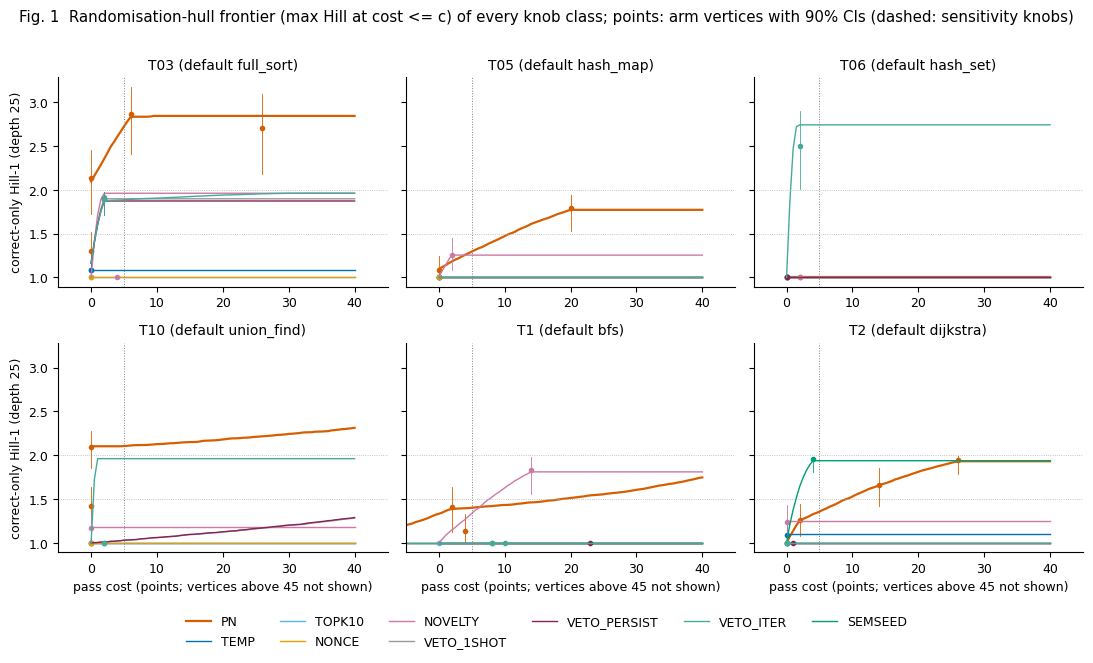

11:17:09|INFO   |figure fig1_hill_vs_cost


In [30]:
fig1(samples, reused)

**Fig. 2: what the programs actually are.** Each bar shows one arm's correct compositions as shares of N = 50; grey
marks the failing and invalid programs.

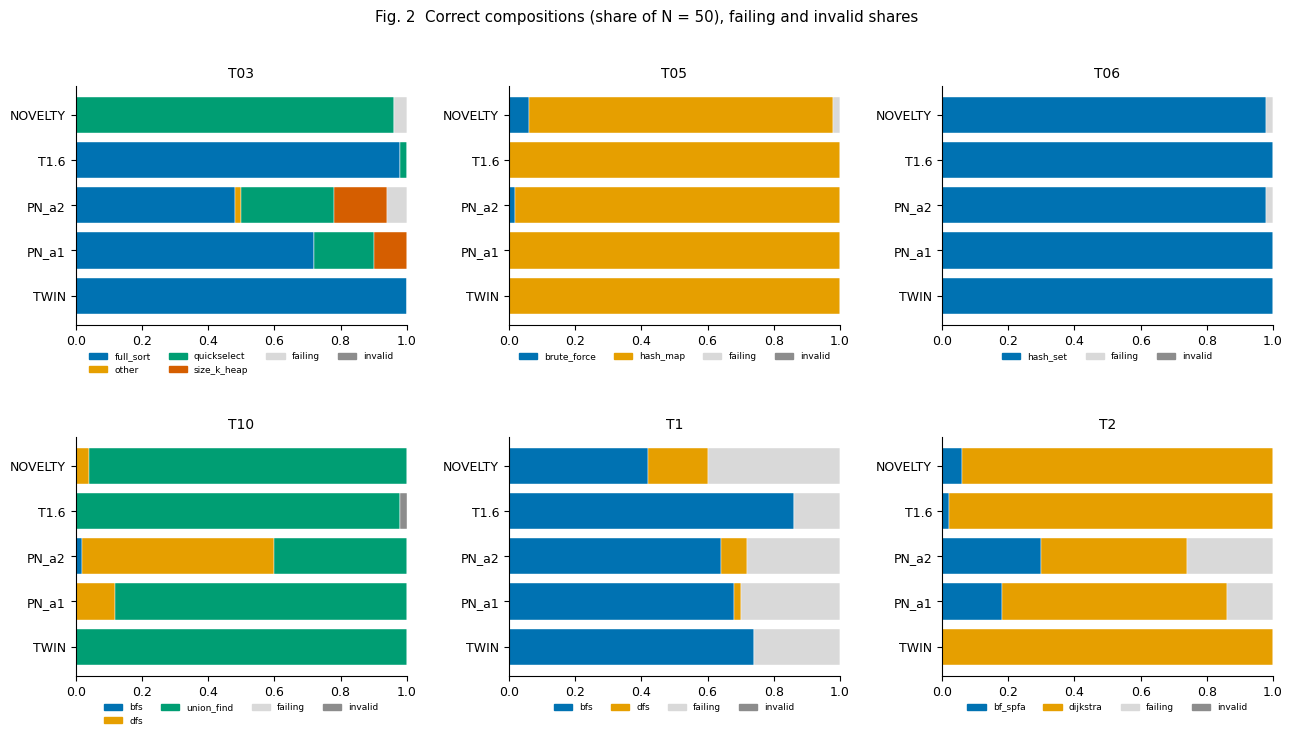

11:17:10|INFO   |figure fig2_compositions


In [31]:
fig2(T)

**Fig. 3: PN dose-response.**

- The off-default share rises with alpha up to 2 on T03, T10, T1 and T2.
- T05 and T06 stay pinned to their default.
- Pass rates collapse at alpha 4-8.

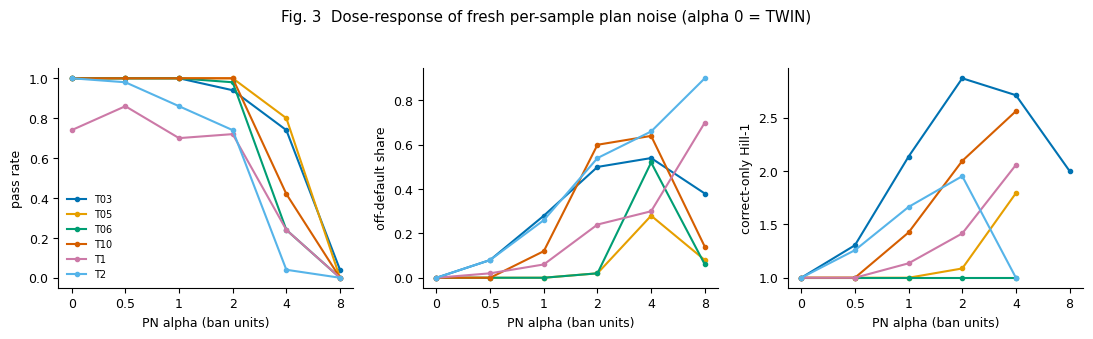

11:17:11|INFO   |figure fig3_alpha_dose_response


In [32]:
fig3()

**Fig. 4: ideas vs phrasings.**

- Temperature arms move up (more ways of writing the default algorithm) without moving right (no new algorithms).
- PN arms move right.

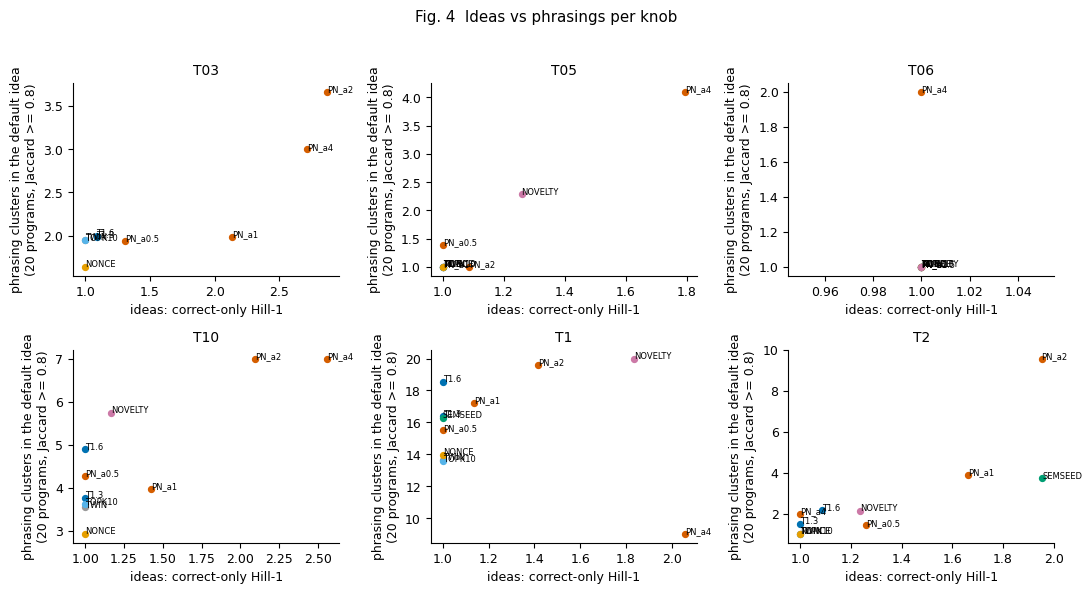

11:17:12|INFO   |figure fig4_ideas_vs_phrasings


In [33]:
fig4()

**Fig. 5: engine check.** Two cells of the iteration-3 screen were re-generated with the screen's own CRN keys. The
per-slot label agreement is 1.00 in all four cells (verdict REPRODUCED).

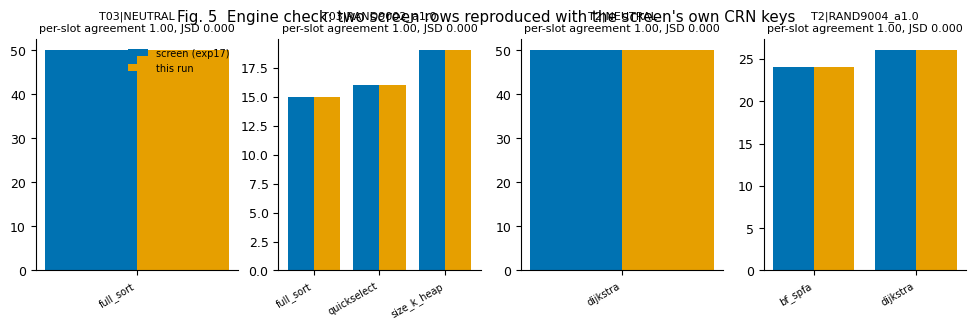

11:17:13|INFO   |figure fig5_engine_check


In [34]:
fig5()

**Fig. 6: the C1 forest plot.** For each task it shows `D_t = H5(PN) − max over NA knobs of H5` with its bootstrap
interval, and the pooled D̄. With the demo's `N_BOOT` the intervals are noisier than the full run's 2,000-replicate
intervals.

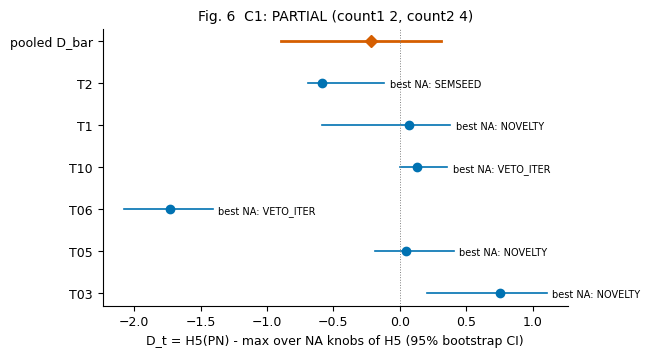

11:17:13|INFO   |figure fig6_forest_Dt


In [35]:
fig6()

## 6. Summary: this notebook vs the full run

The headline tables are formatted as `src/report_numbers.py` does (its `f` / `ci` helpers are copied verbatim), and
each value is set next to the full run's.

- **Point estimates** (H5, best NA knob, D_t): identical to the full run, because they are deterministic.
- **Bootstrap quantities** (intervals, P(H5_PN > H5_best), the verdict's CI criterion): these depend on `N_BOOT`
  and get closer to the full run as the config values approach the originals.

The final plot summarises the experiment's answer to the motivating question, *is temperature the creativity knob?*
It sets the CRN flip rates (code vs algorithm) next to the price of each knob class.

**C1 (pre-registered rule), this notebook (200 bootstrap replicates): PARTIAL** (failed: count1>=3, CI_low>0). count1 = 2/6; count2 = 4/6; D_bar = -0.218 (95% CI [-0.899, 0.310]).

**Full run (2,000 replicates): PARTIAL** (failed: count1>=3, CI_low>0). count1 = 2/6; count2 = 4/6; D_bar = -0.218 (95% CI [-0.893, 0.304]).

| Task (default) | H5 PN | best NA knob | H5 best NA | D_t [95% CI], notebook | D_t [95% CI], full run | P(H5_PN > H5_best), notebook / full | P15 PN | P20 PN |
|---|---|---|---|---|---|---|---|---|
| T03 (full_sort) | 2.72 | NOVELTY | 1.96 | 0.76 [0.21, 1.11] | 0.76 [0.21, 1.16] | 0.99 / 1.00 | 0.0 | 0.0 |
| T05 (hash_map) | 1.29 | NOVELTY | 1.24 | 0.05 [-0.19, 0.40] | 0.05 [-0.20, 0.37] | 0.66 / 0.67 | 11.1 | – |
| T06 (hash_set) | 1.00 | VETO_ITER | 2.73 | -1.73 [-2.08, -1.41] | -1.73 [-2.06, -1.39] | 0.00 / 0.00 | – | – |
| T10 (union_find) | 2.09 | VETO_ITER | 1.96 | 0.13 [-0.00, 0.36] | 0.13 [-0.00, 0.37] | 0.94 / 0.91 | 0.0 | 0.0 |
| T1 (bfs) | 1.42 | NOVELTY | 1.34 | 0.07 [-0.59, 0.38] | 0.07 [-0.57, 0.41] | 0.49 / 0.49 | 18.0 | 49.8 |
| T2 (dijkstra) | 1.35 | SEMSEED | 1.93 | -0.58 [-0.69, -0.12] | -0.58 [-0.69, -0.14] | 0.01 / 0.00 | 9.3 | – |

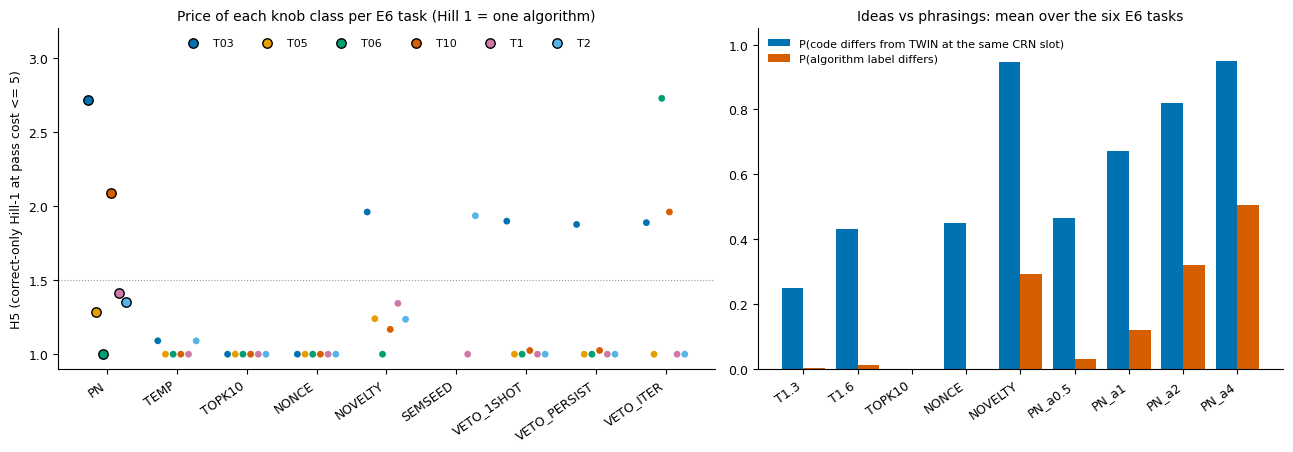

In [36]:
# ---- f / ci from src/report_numbers.py (verbatim) ----
def f(x, nd=2):
    if x is None:
        return "–"
    if isinstance(x, str):
        return x
    return f"{x:.{nd}f}"


def ci(c, nd=2):
    if not c or c[0] is None:
        return "–"
    return f"[{c[0]:.{nd}f}, {c[1]:.{nd}f}]"


c1 = read_json(RESULTS_DIR / "c1.json")
pr = read_json(RESULTS_DIR / "prices.json")
ref = meta["full_run_reference"]
p = c1["primary"]
rp = ref["c1_primary"]
L = []
L.append(f"**C1 (pre-registered rule), this notebook ({N_BOOT} bootstrap replicates): {p['verdict']}**"
         + (f" (failed: {', '.join(p['failed_thresholds'])})" if p["failed_thresholds"] else "") + ". "
         f"count1 = {p['count1']}/6; count2 = {p['count2']}/6; D_bar = {f(p['D_bar'], 3)} (95% CI {ci(p['D_bar_ci95'], 3)}).")
L.append("")
L.append(f"**Full run (2,000 replicates): {rp['verdict']}** (failed: {', '.join(rp['failed_thresholds'])}). "
         f"count1 = {rp['count1']}/6; count2 = {rp['count2']}/6; D_bar = {f(rp['D_bar'], 3)} (95% CI {ci(rp['D_bar_ci95'], 3)}).")
L.append("")
L.append("| Task (default) | H5 PN | best NA knob | H5 best NA | D_t [95% CI], notebook | D_t [95% CI], full run | "
         "P(H5_PN > H5_best), notebook / full | P15 PN | P20 PN |")
L.append("|---|---|---|---|---|---|---|---|---|")
for t in E6_TASKS:
    d = p["per_task"].get(t, {})
    r = ref["c1_per_task"].get(t, {})
    pn = pr.get(t, {}).get("PN", {})
    L.append(f"| {t} ({DEFAULT[t]}) | {f(d.get('H5_PN'))} | {d.get('best_na') or '–'} | {f(d.get('H5_best'))} | "
             f"{f(d.get('D_t'))} {ci(d.get('D_t_boot_ci95'))} | {f(r.get('D_t'))} {ci(r.get('D_t_boot_ci95'))} | "
             f"{f(d.get('P_boot_PN_gt_best'))} / {f(r.get('P_boot_PN_gt_best'))} | {f(pn.get('P15'), 1)} | {f(pn.get('P20'), 1)} |")
display(Markdown("\n".join(L)))

# final visualization: price of each knob class (H5) and how each knob perturbs the programs (CRN flips)
fl = read_json(RESULTS_DIR / "flips.json")
classes = ["PN", "TEMP", "TOPK10", "NONCE", "NOVELTY", "SEMSEED", "VETO_1SHOT", "VETO_PERSIST", "VETO_ITER"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
for j, t in enumerate(E6_TASKS):
    for i, c in enumerate(classes):
        v = pr[t].get(c, {}).get("H5")
        if v is None:
            continue
        ax.scatter(i + (j - 2.5) * 0.11, v, color=OKABE[j], s=46 if c == "PN" else 24,
                   edgecolor="k" if c == "PN" else "none", zorder=3, label=t if i == 0 else None)
ax.axhline(1.5, color="0.6", ls=":", lw=0.8)
ax.set_xticks(range(len(classes)))
ax.set_xticklabels(classes, rotation=35, ha="right")
ax.set_ylabel("H5 (correct-only Hill-1 at pass cost <= 5)")
ax.set_title("Price of each knob class per E6 task (Hill 1 = one algorithm)")
ax.set_ylim(0.9, 3.2)
ax.legend(frameon=False, fontsize=8, ncol=6, loc="upper center")
ax = axes[1]
arms = ["T1.3", "T1.6", "TOPK10", "NONCE", "NOVELTY", "PN_a0.5", "PN_a1", "PN_a2", "PN_a4"]
pc = [np.mean([fl[f"{t}|{a}"]["P_code_differs"] for t in E6_TASKS if f"{t}|{a}" in fl]) for a in arms]
plb = [np.mean([fl[f"{t}|{a}"]["P_label_differs"] for t in E6_TASKS if f"{t}|{a}" in fl]) for a in arms]
x = np.arange(len(arms))
ax.bar(x - 0.2, pc, 0.4, color=OKABE[0], label="P(code differs from TWIN at the same CRN slot)")
ax.bar(x + 0.2, plb, 0.4, color=OKABE[3], label="P(algorithm label differs)")
ax.set_xticks(x)
ax.set_xticklabels(arms, rotation=35, ha="right")
ax.set_ylim(0, 1.05)
ax.set_title("Ideas vs phrasings: mean over the six E6 tasks")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()